# Quantum Optimisation of Retroactive Rebate Programs

## Purpose

Retroactive (all-units) rebate tiers are among the most common incentive structures in B2B commercial strategy, and among the hardest to design well. When a customer's volume crosses a threshold, the higher rebate rate applies to **every unit purchased in the period**, not just the units above it. That creates discontinuities ("cliffs") in both the customer's net price and the supplier's margin. It also turns the design of a program's thresholds and rates into a combinatorial optimisation problem that scales poorly as tiers, customers and constraints grow.

This notebook asks one research question:

> **Can rebate program design be formulated as a quantum optimisation problem, and does a hybrid quantum-classical approach built on NVIDIA CUDA-Q offer a useful new way to construct retroactive tier structures?**

## Why retroactive tiers matter

A retroactive tier schedule with thresholds $0 = t_0 < t_1 < \dots < t_K$ and rates $r_0 < r_1 < \dots < r_K$ pays a rebate of

$$
R(q) = r_k \, q \quad \text{for } t_k \le q < t_{k+1}
$$

on period volume $q$. Unlike an incremental schedule, $R(q)$ is discontinuous. At each threshold the payout jumps by

$$
\Delta R_k = (r_k - r_{k-1})\, t_k ,
$$

so the effective marginal price just below a threshold can become negative. This gives suppliers behavioural leverage over customers near a threshold. It also creates a risk of margin leakage when thresholds are badly placed, and a discrete, non-convex design problem across a portfolio of customers.

## Structure of the notebook

Each Part has a theory section followed by a single Python cell that runs the examples in CUDA-Q. The Python cells build on each other, so run them in order.

**Part 1: Basics of Retroactive Volume Rebates**

- 1.1 Constructing a 3-tier program
- 1.2 Calculating the rebate across the year
- 1.3 The tier cliff

**Part 2: A Basic Introduction to Qubits**

- 2.1 A single qubit
- 2.2 The Bloch sphere
- 2.3 Two qubits
- 2.4 The CNOT operation
- 2.5 Entanglement

**Part 3: Introduction to Quantum Gates and Quantum Circuits**

- 3.1 What is a gate?
- 3.2 The essential single-qubit gates
- 3.3 Gates can be undone
- 3.4 Interference: why phase matters
- 3.5 Two-qubit gates
- 3.6 Quantum circuits

**Part 4: The Bernoulli Random Variable**

- 4.1 What is a Bernoulli variable?
- 4.2 A rebate example
- 4.3 Loading a probability into a qubit
- 4.4 Estimating p by measuring
- 4.5 Several customers

**Part 5: The Grover Operator**

- 5.1 The idea: amplifying the outcome we care about
- 5.2 Building the Grover operator
- 5.3 The picture: a rotation
- 5.4 A worked example
- 5.5 Several customers
- 5.6 Two uses of the Grover operator

**Part 6: Quantum Amplitude Estimation**

- 6.1 The goal
- 6.2 The key idea: measure the rotation, not the coin
- 6.3 How the estimate is made
- 6.4 Counting the cost fairly
- 6.5 What this means for rebates, and the caveats

**Part 7: A New Quantum Approach to Constructing Rebate Programs**

- 7.1 The rebate program and the design choices
- 7.2 One qubit per customer
- 7.3 Linking customers through a common demand driver
- 7.4 Constructing the circuit
- 7.5 Estimating the risk with amplitude estimation
- 7.6 Choosing the design
- 7.7 What is quantum here, and the caveats

## Scope

This is exploratory research. All quantum results come from simulation, and no quantum advantage is claimed. The aim is to show that rebate design maps naturally onto quantum optimisation, and to compare it honestly against classical baselines.

# Part 1: Basics of Retroactive Volume Rebates

A **volume rebate** is a payment from a supplier back to a customer once the customer's purchase volume over an agreed period (here, one year) reaches set thresholds. In a **retroactive** (all-units) rebate, reaching a higher tier moves *all* volume in the period to the higher rate, including volume bought before the threshold was crossed.

## 1.1 Constructing a 3-tier program

Consider a single product sold at a list price of **£50 per unit**. The supplier offers this annual program, with the rebate calculated as a percentage of spend:

| Tier | Annual volume (units) | Rebate rate |
|---|---|---|
| 1 | 0 – 9,999 | 0% |
| 2 | 10,000 – 24,999 | 2% |
| 3 | 25,000 + | 4% |

Formally, with thresholds $t_1 = 0$, $t_2 = 10{,}000$, $t_3 = 25{,}000$ and rates $r_1 = 0$, $r_2 = 0.02$, $r_3 = 0.04$, the rate that applies to cumulative volume $Q$ is

$$
r(Q) = r_k \quad \text{for } t_k \le Q < t_{k+1},
$$

and the rebate owed on cumulative spend $S = p\,Q$ is

$$
R(Q) = r(Q)\, S .
$$

## 1.2 Calculating the rebate across the year

Rebates are usually settled periodically (here, quarterly) against **cumulative year-to-date (YTD)** volume. Because the rate is retroactive, each time the customer moves up a tier, earlier purchases must be re-rated at the new rate. This catch-up payment is the **true-up**.

In each quarter $n$:

$$
E_n = r(Q_n)\, S_n \qquad\text{(cumulative entitlement to date)}
$$

$$
P_n = E_n - E_{n-1} \qquad\text{(payment due this quarter, including any true-up)}
$$

Suppose the customer buys the following volumes:

| Quarter | Units | Spend | YTD units | YTD spend | Tier reached | YTD entitlement $E_n$ | Payment $P_n$ |
|---|---|---|---|---|---|---|---|
| Q1 | 6,000 | £300,000 | 6,000 | £300,000 | 1 (0%) | £0 | £0 |
| Q2 | 7,000 | £350,000 | 13,000 | £650,000 | 2 (2%) | £13,000 | £13,000 |
| Q3 | 8,000 | £400,000 | 21,000 | £1,050,000 | 2 (2%) | £21,000 | £8,000 |
| Q4 | 9,000 | £450,000 | 30,000 | £1,500,000 | 3 (4%) | £60,000 | £39,000 |
| **Total** | **30,000** | **£1,500,000** | | | | | **£60,000** |

**The true-ups:**

- **Q2.** The customer crosses 10,000 units. The Q2 payment of £13,000 is 2% of Q2 spend (£7,000) plus a **£6,000 true-up** that re-rates Q1's £300,000 from 0% to 2%.
- **Q3.** The customer stays in Tier 2, so there is no true-up. The payment is 2% of Q3 spend: £8,000.
- **Q4.** The customer crosses 25,000 units. The Q4 payment of £39,000 is 4% of Q4 spend (£18,000) plus a **£21,000 true-up** that re-rates the £1,050,000 bought in Q1–Q3 from 2% to 4%.

**Annual outcome for the supplier:**

$$
\text{Net revenue} = S - R = £1{,}500{,}000 - £60{,}000 = £1{,}440{,}000
$$

This gives an effective net price of $£1{,}440{,}000 / 30{,}000 = £48.00$ per unit, an overall discount of 4%.

## 1.3 The tier cliff

The retroactive structure creates a discontinuity at every threshold. Just below and just above Tier 3:

| Annual units | Spend | Rate | Rebate | Net revenue |
|---|---|---|---|---|
| 24,999 | £1,249,950 | 2% | £24,999 | £1,224,951 |
| 25,000 | £1,250,000 | 4% | £50,000 | £1,200,000 |

Selling **one more unit** raises the rebate by about **£25,000** and *reduces* the supplier's net revenue by £24,951. In general, the size of the cliff at threshold $t_k$ is

$$
\Delta R_k = (r_k - r_{k-1})\, p\, t_k = (0.04 - 0.02) \times £50 \times 25{,}000 = £25{,}000 .
$$

The cliff has two sides:

- **For the customer**, it is a strong incentive to push volume over the threshold. This is the behavioural lever the program is designed to create.
- **For the supplier**, it is a source of margin risk. A threshold placed where customers would have landed anyway pays the higher rate on the whole year's volume for no change in behaviour.

Choosing where to place thresholds and how to set rates, across many customers with uncertain volumes, is the optimisation problem the rest of this notebook develops.

In [1]:
# --- 1.1 The rebate program ---------------------------------------------

price = 50  # £ per unit

# Each tier: (minimum annual units, rebate rate)
tiers = [
    (0,      0.00),  # Tier 1
    (10_000, 0.02),  # Tier 2
    (25_000, 0.04),  # Tier 3
]


def rebate_rate(units):
    """Return the rate for the highest tier the volume has reached."""
    rate = 0.0
    for threshold, tier_rate in tiers:
        if units >= threshold:
            rate = tier_rate
    return rate


def rebate(units):
    """Retroactive rebate: the tier rate applies to ALL spend."""
    return rebate_rate(units) * units * price


# --- 1.2 Calculating the rebate across the year ---------------------------

quarterly_units = {"Q1": 6_000, "Q2": 7_000, "Q3": 8_000, "Q4": 9_000}

ytd_units = 0
paid_so_far = 0

print(f"{'Qtr':<4}{'Units':>8}{'YTD units':>11}{'Rate':>7}{'Entitlement':>13}{'Payment':>10}{'True-up':>10}")

for quarter, units in quarterly_units.items():
    rate_before = rebate_rate(ytd_units)       # rate before this quarter's purchases
    ytd_units += units

    entitlement = rebate(ytd_units)            # E_n: total owed on YTD spend
    payment = entitlement - paid_so_far        # P_n = E_n - E_(n-1)
    true_up = (rebate_rate(ytd_units) - rate_before) * (ytd_units - units) * price  # re-rating earlier spend
    paid_so_far = entitlement

    print(f"{quarter:<4}{units:>8,}{ytd_units:>11,}{rebate_rate(ytd_units):>7.0%}"
          f"{entitlement:>13,.0f}{payment:>10,.0f}{true_up:>10,.0f}")

total_spend = ytd_units * price
total_rebate = rebate(ytd_units)
net_revenue = total_spend - total_rebate

print()
print(f"Total spend:       £{total_spend:,.0f}")
print(f"Total rebate:      £{total_rebate:,.0f}")
print(f"Net revenue:       £{net_revenue:,.0f}")
print(f"Net price per unit: £{net_revenue / ytd_units:.2f}")


# --- 1.3 The tier cliff ---------------------------------------------------

print()
for units in [24_999, 25_000]:
    spend = units * price
    print(f"{units:,} units -> rebate £{rebate(units):,.0f}, net revenue £{spend - rebate(units):,.0f}")

print(f"Cliff at 25,000 units: £{rebate(25_000) - rebate(24_999):,.0f}")

Qtr    Units  YTD units   Rate  Entitlement   Payment   True-up
Q1     6,000      6,000     0%            0         0         0
Q2     7,000     13,000     2%       13,000    13,000     6,000
Q3     8,000     21,000     2%       21,000     8,000         0
Q4     9,000     30,000     4%       60,000    39,000    21,000

Total spend:       £1,500,000
Total rebate:      £60,000
Net revenue:       £1,440,000
Net price per unit: £48.00

24,999 units -> rebate £24,999, net revenue £1,224,951
25,000 units -> rebate £50,000, net revenue £1,200,000
Cliff at 25,000 units: £25,001


# Part 2: A Basic Introduction to Qubits

## 2.1 A single qubit

A classical **bit** is always either `0` or `1`. A **qubit** can also be `0` or `1`, which we write as the states $|0\rangle$ and $|1\rangle$. It can also be in a **superposition**, a blend of the two:

$$
|\psi\rangle = \alpha\,|0\rangle + \beta\,|1\rangle
$$

The numbers $\alpha$ and $\beta$ are called **amplitudes**. They set the probability of each result when the qubit is measured:

$$
P(0) = |\alpha|^2, \qquad P(1) = |\beta|^2, \qquad |\alpha|^2 + |\beta|^2 = 1
$$

**Measurement** always gives a plain `0` or `1`, never a blend. Once measured, the qubit stays in the state that was observed, and the superposition is gone.

*Example:* with $\alpha = \beta = \tfrac{1}{\sqrt{2}}$, the qubit is an equal blend. Measuring it gives `0` half the time and `1` half the time, like a fair coin toss.

## 2.2 The Bloch sphere

A single qubit can be pictured as an **arrow pointing from the centre of a sphere to its surface**. This is the Bloch sphere.

- The **north pole** is $|0\rangle$.
- The **south pole** is $|1\rangle$.
- Every other point on the surface is a superposition.

The direction of the arrow is given by two angles: $\theta$, measured down from the north pole, and $\phi$, measured around the equator. In terms of these angles, the state is

$$
|\psi\rangle = \cos\!\left(\tfrac{\theta}{2}\right)|0\rangle + e^{i\phi}\sin\!\left(\tfrac{\theta}{2}\right)|1\rangle
$$

**Measuring on the Bloch sphere.** A measurement asks one question: *is the arrow up or down?* The closer the arrow is to a pole, the more likely that result:

$$
P(0) = \cos^2\!\left(\tfrac{\theta}{2}\right), \qquad P(1) = \sin^2\!\left(\tfrac{\theta}{2}\right)
$$

| Arrow position | $\theta$ | $P(0)$ | $P(1)$ |
|---|---|---|---|
| North pole | 0° | 100% | 0% |
| Upper half | 60° | 75% | 25% |
| Equator | 90° | 50% | 50% |
| South pole | 180° | 0% | 100% |

After a measurement, the arrow **snaps to the pole** matching the result. The angle $\phi$ has no effect on these probabilities. It becomes important once qubits interact, but it can be set aside for now.

## 2.3 Two qubits

With two qubits there are **four** basic states, one for each pair of classical values:

$$
|00\rangle, \quad |01\rangle, \quad |10\rangle, \quad |11\rangle
$$

A two-qubit state can be a superposition of all four, with one amplitude each:

$$
|\psi\rangle = a\,|00\rangle + b\,|01\rangle + c\,|10\rangle + d\,|11\rangle, \qquad |a|^2 + |b|^2 + |c|^2 + |d|^2 = 1
$$

Measuring both qubits gives one of the four pairs, with probability $|a|^2$, $|b|^2$, $|c|^2$ or $|d|^2$.

The number of states grows quickly. Every extra qubit **doubles** the number of basic states, so $n$ qubits hold amplitudes for $2^n$ combinations at once. With 10 qubits that is 1,024 combinations, and with 50 qubits it is about $10^{15}$. This is what makes qubits interesting for search problems like choosing rebate tiers.

## 2.4 The CNOT operation

The **CNOT** (controlled-NOT) acts on two qubits: a **control** and a **target**.

> *If the control is `1`, flip the target. Otherwise, do nothing.*

| Before (control, target) | After |
|---|---|
| $\lvert 00\rangle$ | $\lvert 00\rangle$ |
| $\lvert 01\rangle$ | $\lvert 01\rangle$ |
| $\lvert 10\rangle$ | $\lvert 11\rangle$ |
| $\lvert 11\rangle$ | $\lvert 10\rangle$ |

With plain `0`s and `1`s, this behaves just like a classical "if" statement. Something new happens when the control is in a **superposition**.

## 2.5 Entanglement

Start with the control in an equal blend and the target at $|0\rangle$:

$$
\tfrac{1}{\sqrt{2}}\big(|0\rangle + |1\rangle\big) \otimes |0\rangle = \tfrac{1}{\sqrt{2}}\big(|00\rangle + |10\rangle\big)
$$

Apply CNOT. The $|00\rangle$ part is unchanged, and the $|10\rangle$ part becomes $|11\rangle$:

$$
\tfrac{1}{\sqrt{2}}\big(|00\rangle + |11\rangle\big)
$$

This is an **entangled** state, called a *Bell state*. Measuring it gives:

| Result | Probability |
|---|---|
| `00` | 50% |
| `11` | 50% |
| `01` or `10` | 0% |

Each qubit on its own is still a 50/50 coin toss, but **the two results always match**. Measuring one qubit immediately tells you the other.

**On the Bloch sphere,** the two qubits can no longer be drawn as two separate arrows, because neither qubit has a state of its own; the information is held in the *relationship* between them. If you look at just one qubit, its arrow shrinks to the **centre** of the sphere. That represents a completely random result that depends entirely on its partner.

## Summary

| Idea | In plain terms |
|---|---|
| Qubit | A bit that can be a blend of `0` and `1` |
| Amplitudes | Numbers that set the odds of each result |
| Measurement | Always gives `0` or `1`, and fixes the qubit in that state |
| Bloch sphere | An arrow for one qubit: up is `0`, down is `1`, and height sets the odds |
| Two qubits | Four combinations; $n$ qubits give $2^n$ |
| CNOT | Flip the target if the control is `1` |
| Entanglement | Linked qubits whose results are correlated and can't be described separately |

Single qubit: tilt the arrow, then measure
 theta   alpha    beta  P(0) theory  P(0) measured
    0°   1.000   0.000         100%           100%
   60°   0.866   0.500          75%            73%
   90°   0.707   0.707          50%            50%
  180°   0.000   1.000           0%             0%


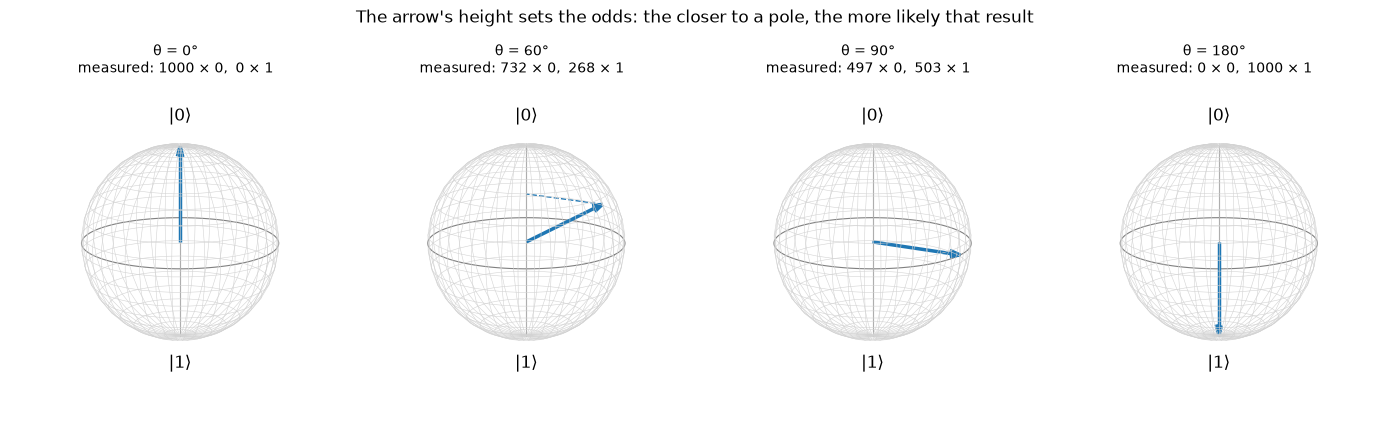


CNOT truth table (control, target)
  |00>  ->  |00>
  |01>  ->  |01>
  |10>  ->  |11>
  |11>  ->  |10>


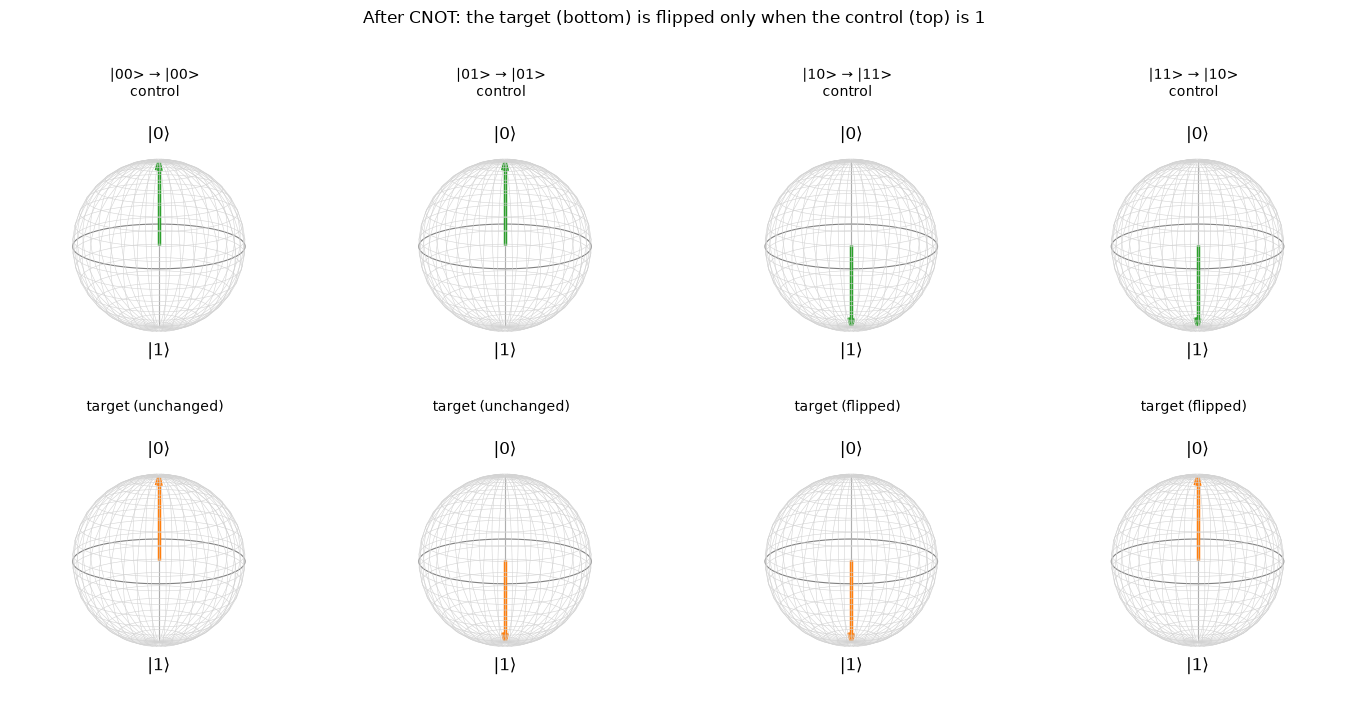


Entangled (Bell) state amplitudes
  |00>: 0.707   (probability 50%)
  |01>: 0.000   (probability 0%)
  |10>: 0.000   (probability 0%)
  |11>: 0.707   (probability 50%)

Measured 1000 times:
  00: 481
  01: 0
  10: 0
  11: 519
The two qubits always agree: only 00 and 11 appear.


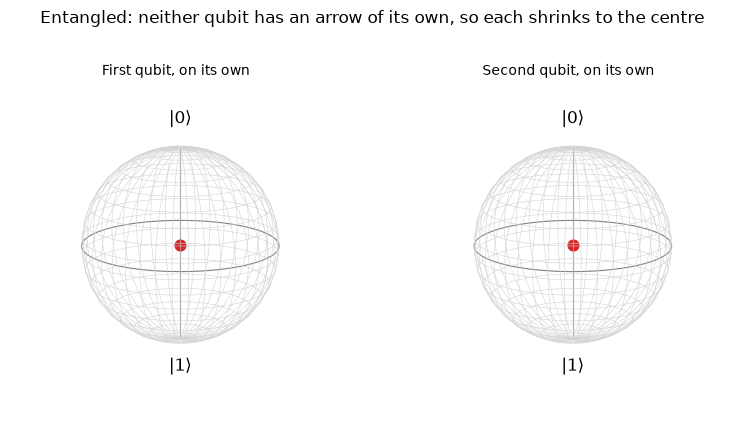

In [1]:
#Introduction to cubits, bloch sphere, CNOT and entanglement 
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)  # hide CUDA-Q API-change notice

import cudaq
import numpy as np
import matplotlib.pyplot as plt

SHOTS = 1000  # how many times to prepare and measure each state


# --- Helpers for drawing the Bloch sphere ------------------------------------

def qubit_on_its_own(state, which):
    """2x2 density matrix for one qubit of a 1- or 2-qubit state."""
    state = np.array(state)
    if len(state) == 2:
        return np.outer(state, state.conj())
    grid = state.reshape(2, 2).T            # CUDA-Q stores qubit 0 as the last binary digit
    if which == 1:                          # rows = the qubit we want to look at
        grid = grid.T
    return grid @ grid.conj().T


def bloch_vector(rho):
    """Arrow (x, y, z) for a single qubit. Height z = P(0) - P(1)."""
    return 2 * rho[1, 0].real, 2 * rho[1, 0].imag, (rho[0, 0] - rho[1, 1]).real


def draw_bloch(ax, rho, title, colour="tab:blue"):
    """Draw one Bloch sphere with the qubit's arrow."""
    u, v = np.mgrid[0:2 * np.pi:40j, 0:np.pi:20j]
    ax.plot_wireframe(np.cos(u) * np.sin(v), np.sin(u) * np.sin(v), np.cos(v),
                      color="lightgrey", linewidth=0.4)
    t = np.linspace(0, 2 * np.pi, 100)
    ax.plot(np.cos(t), np.sin(t), 0, color="grey", linewidth=0.8)        # equator
    ax.plot([0, 0], [0, 0], [-1, 1], color="grey", linewidth=0.8)        # vertical axis
    ax.text(0, 0, 1.25, r"$|0\rangle$", ha="center", fontsize=12)
    ax.text(0, 0, -1.35, r"$|1\rangle$", ha="center", fontsize=12)

    x, y, z = bloch_vector(rho)
    if np.sqrt(x**2 + y**2 + z**2) < 0.01:
        ax.scatter([0], [0], [0], color=colour, s=60)                   # arrow shrunk to a point
    else:
        ax.quiver(0, 0, 0, x, y, z, color=colour, linewidth=2.5, arrow_length_ratio=0.12)
        ax.plot([x, 0], [y, 0], [z, z], color=colour, linestyle="--", linewidth=1)  # height

    ax.set_title(title, fontsize=10)
    ax.set_xlim(-1, 1); ax.set_ylim(-1, 1); ax.set_zlim(-1, 1)
    ax.set_box_aspect([1, 1, 1])
    ax.view_init(elev=15, azim=-60)
    ax.set_axis_off()


# --- 2.1 / 2.2 A single qubit on the Bloch sphere ---------------------------

@cudaq.kernel
def one_qubit(theta: float):
    q = cudaq.qubit()   # starts at the north pole, |0>
    ry(theta, q)        # tilt the arrow down from the north pole by angle theta


angles = [0, 60, 90, 180]

print("Single qubit: tilt the arrow, then measure")
print(f"{'theta':>6}{'alpha':>8}{'beta':>8}{'P(0) theory':>13}{'P(0) measured':>15}")

fig = plt.figure(figsize=(14, 4))
for i, degrees in enumerate(angles):
    theta = np.radians(degrees)

    state = cudaq.get_state(one_qubit, theta)                   # the two amplitudes
    alpha, beta = np.array(state)
    counts = cudaq.sample(one_qubit, theta, shots_count=SHOTS)  # measure SHOTS times

    print(f"{degrees:>5}°{alpha.real:>8.3f}{beta.real:>8.3f}"
          f"{abs(alpha)**2:>13.0%}{counts.count('0') / SHOTS:>15.0%}")

    ax = fig.add_subplot(1, len(angles), i + 1, projection="3d")
    draw_bloch(ax, qubit_on_its_own(state, 0),
               f"θ = {degrees}°\nmeasured: {counts.count('0')} × 0,  {counts.count('1')} × 1")

fig.suptitle("The arrow's height sets the odds: the closer to a pole, the more likely that result", y=1.05)
plt.tight_layout()
plt.show()


# --- 2.3 / 2.4 Two qubits and the CNOT --------------------------------------

@cudaq.kernel
def cnot_example(control: int, target: int):
    q = cudaq.qvector(2)   # two qubits, both starting at |0>
    if control == 1:
        x(q[0])            # set the control to 1
    if target == 1:
        x(q[1])            # set the target to 1
    x.ctrl(q[0], q[1])     # CNOT: flip the target if the control is 1


print("\nCNOT truth table (control, target)")

fig = plt.figure(figsize=(14, 7))
inputs = [(0, 0), (0, 1), (1, 0), (1, 1)]
for i, (control, target) in enumerate(inputs):
    result = cudaq.sample(cnot_example, control, target).most_probable()
    print(f"  |{control}{target}>  ->  |{result}>")

    state = cudaq.get_state(cnot_example, control, target)
    ax = fig.add_subplot(2, 4, i + 1, projection="3d")
    draw_bloch(ax, qubit_on_its_own(state, 0), f"|{control}{target}> → |{result}>\ncontrol", "tab:green")
    ax = fig.add_subplot(2, 4, i + 5, projection="3d")
    flipped = "flipped" if control == 1 else "unchanged"
    draw_bloch(ax, qubit_on_its_own(state, 1), f"target ({flipped})", "tab:orange")

fig.suptitle("After CNOT: the target (bottom) is flipped only when the control (top) is 1", y=1.02)
plt.tight_layout()
plt.show()


# --- 2.5 Entanglement --------------------------------------------------------

@cudaq.kernel
def bell():
    q = cudaq.qvector(2)
    h(q[0])                # put the control into an equal blend of 0 and 1
    x.ctrl(q[0], q[1])     # CNOT links the target to the control


state = cudaq.get_state(bell)
print("\nEntangled (Bell) state amplitudes")
for label, amp in zip(["00", "01", "10", "11"], np.array(state)):
    print(f"  |{label}>: {amp.real:.3f}   (probability {abs(amp)**2:.0%})")

counts = cudaq.sample(bell, shots_count=SHOTS)
print(f"\nMeasured {SHOTS} times:")
for outcome in ["00", "01", "10", "11"]:
    print(f"  {outcome}: {counts.count(outcome)}")
print("The two qubits always agree: only 00 and 11 appear.")

fig = plt.figure(figsize=(8, 4))
for i, name in enumerate(["First qubit", "Second qubit"]):
    ax = fig.add_subplot(1, 2, i + 1, projection="3d")
    draw_bloch(ax, qubit_on_its_own(state, i), f"{name}, on its own", "tab:red")

fig.suptitle("Entangled: neither qubit has an arrow of its own, so each shrinks to the centre", y=1.05)
plt.tight_layout()
plt.show()


# Part 3: Introduction to Quantum Gates and Quantum Circuits

## 3.1 What is a gate?

A **quantum gate** is an operation that changes a qubit's state. On the Bloch sphere, every single-qubit gate is a **rotation**: it turns the arrow to a new position without changing its length.

Behind the picture, a gate is a small table of numbers (a matrix) that mixes the two amplitudes. For example, the X gate swaps them:

$$
X \begin{pmatrix} \alpha \\ \beta \end{pmatrix} = \begin{pmatrix} 0 & 1 \\ 1 & 0 \end{pmatrix}\begin{pmatrix} \alpha \\ \beta \end{pmatrix} = \begin{pmatrix} \beta \\ \alpha \end{pmatrix}
$$

## 3.2 The essential single-qubit gates

| Gate | What it does | On the Bloch sphere | Starting from $\lvert 0\rangle$ |
|---|---|---|---|
| **X** (NOT) | Swaps $\alpha$ and $\beta$ | Half-turn, flipping top and bottom | $\lvert 1\rangle$: always measures `1` |
| **H** (Hadamard) | Creates an equal blend | Moves a pole to the equator | $\tfrac{1}{\sqrt2}(\lvert 0\rangle + \lvert 1\rangle)$: 50/50 |
| **Z** (phase flip) | Flips the sign of $\beta$ | Half-turn around the vertical axis | No visible change: still measures `0` |
| **RY($\theta$)** | Tilts the arrow by any angle | Rotates down from the north pole by $\theta$ | $P(1) = \sin^2(\theta/2)$ |

The matrices behind them are:

$$
X = \begin{pmatrix} 0 & 1 \\ 1 & 0 \end{pmatrix}, \quad
H = \tfrac{1}{\sqrt2}\begin{pmatrix} 1 & 1 \\ 1 & -1 \end{pmatrix}, \quad
Z = \begin{pmatrix} 1 & 0 \\ 0 & -1 \end{pmatrix}, \quad
R_Y(\theta) = \begin{pmatrix} \cos\frac{\theta}{2} & -\sin\frac{\theta}{2} \\ \sin\frac{\theta}{2} & \cos\frac{\theta}{2} \end{pmatrix}
$$

**RY is the most important gate for this notebook.** A single number, the angle $\theta$, sets the odds of measuring `1` anywhere between 0% and 100%. This is how a probability (such as "the chance a customer reaches Tier 3") gets loaded into a qubit.

**Z shows that odds aren't the whole story.** Z changes the sign of $\beta$, which moves the arrow around the equator, but the measurement odds stay the same. That hidden sign, the **phase**, still matters, as 3.4 shows.

## 3.3 Gates can be undone

Every gate is a rotation, so every gate can be reversed by rotating back. X, H and Z are each their own reverse:

$$
X\,X = H\,H = Z\,Z = \text{do nothing}
$$

**Measurement is the only step that can't be undone.** It collapses the qubit to `0` or `1`, and the amplitudes are lost. For this reason, a calculation keeps its qubits unmeasured for as long as possible and measures only at the very end.

## 3.4 Interference: why phase matters

Compare two short sequences, both starting from $|0\rangle$:

| Sequence | Step by step | Result |
|---|---|---|
| H, then H | $\lvert 0\rangle \to \tfrac{1}{\sqrt2}(\lvert 0\rangle + \lvert 1\rangle) \to \lvert 0\rangle$ | Always `0` |
| H, then Z, then H | $\lvert 0\rangle \to \tfrac{1}{\sqrt2}(\lvert 0\rangle + \lvert 1\rangle) \to \tfrac{1}{\sqrt2}(\lvert 0\rangle - \lvert 1\rangle) \to \lvert 1\rangle$ | Always `1` |

In the middle, both sequences measure 50/50; the only difference is a minus sign. Yet the final results are opposite. Amplitudes can **add up** (constructive interference) or **cancel out** (destructive interference), just like waves.

This is the core idea behind quantum algorithms: arrange the gates so that the amplitudes of wrong answers cancel and the amplitudes of the right answer add up. A quantum computer can hold many possible answers in superposition at once, but measuring it returns only one of them, picked at random, so superposition alone gives no advantage. The skill in designing a quantum algorithm is choosing a sequence of gates that uses interference to raise the probability of the answer we want before measuring, so that it becomes the result most likely to appear.

## 3.5 Two-qubit gates

**CNOT** (from Part 2) flips the target when the control is `1`.

Any gate can be given a control in the same way. The **controlled-RY** rotates the target by $\theta$ *only* when the control is `1`. This lets one qubit's value decide how likely another qubit is to be `1`, which is exactly the kind of "if this, then that probability" logic needed to model customers moving between rebate tiers.

## 3.6 Quantum circuits

A **quantum circuit** is a recipe: a list of gates applied to qubits in order. It is drawn as a diagram:

- Each **horizontal line** is one qubit.
- **Time runs left to right.**
- Each **box** is a gate.
- A **dot joined to a box** is a controlled gate. The dot marks the control.

The Bell state from Part 2 is this circuit:

```
     ╭───╮
q0 : ┤ h ├──●──
     ╰───╯╭─┴─╮
q1 : ─────┤ x ├
          ╰───╯
```

Reading left to right:

| Step | Gate | State |
|---|---|---|
| Start | | $\lvert 00\rangle$ |
| 1 | H on q0 | $\tfrac{1}{\sqrt2}(\lvert 00\rangle + \lvert 10\rangle)$ |
| 2 | CNOT (q0 controls q1) | $\tfrac{1}{\sqrt2}(\lvert 00\rangle + \lvert 11\rangle)$ |
| End | Measure both | `00` or `11`, 50/50 |

In CUDA-Q, a circuit is written as a **kernel**: a Python function marked with `@cudaq.kernel`. Calling `cudaq.draw` on a kernel prints its circuit diagram.

## Summary

| Idea | In plain terms |
|---|---|
| Gate | A rotation of the qubit's arrow |
| X, H, Z | Flip, blend, and phase-flip |
| RY($\theta$) | Dial in any probability of measuring `1` |
| Reversibility | Every gate can be undone; measurement cannot |
| Phase and interference | Hidden signs that make amplitudes add up or cancel out |
| Controlled gate | A gate that acts only when its control qubit is `1` |
| Circuit | A recipe of gates, read left to right, measured at the end |

Single-qubit gates, each starting from |0>
Gate         alpha    beta   P(0)   P(1)   measured 0 / 1
X            0.000   1.000     0%   100%         0 / 1000
H            0.707   0.707    50%    50%       490 / 510
H then Z     0.707  -0.707    50%    50%       510 / 490
RY(60°)      0.866   0.500    75%    25%       753 / 247


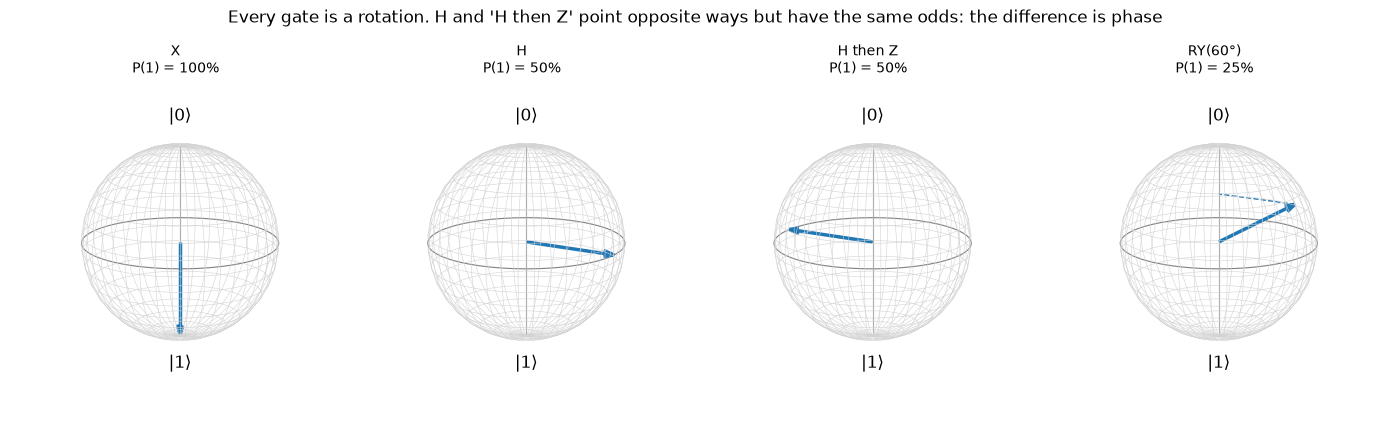


Sequences of gates, each starting from |0>
Sequence  final state                measured 0 / 1
H         +0.707|0>  +0.707|1>           498 / 502
X, X      +1.000|0>                     1000 / 0
H, H      +1.000|0>                     1000 / 0
H, Z, H   +1.000|1>                        0 / 1000


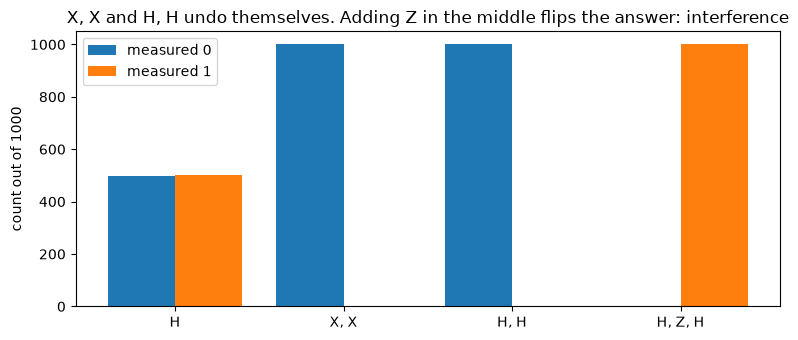


Controlled-RY(60°) circuit:
     ╭───╮             
q0 : ┤ h ├──────●──────
     ╰───╯╭─────┴─────╮
q1 : ─────┤ ry(1.047) ├
          ╰───────────╯

Outcome    theory  measured
  00        50.0%     49.7%
  01         0.0%      0.0%
  10        37.5%     37.3%
  11        12.5%     13.0%

When the control is 0, the target is never 1 (count of 01 = 0).
When the control is 1, the target is 1 in 26% of cases (theory 25%).


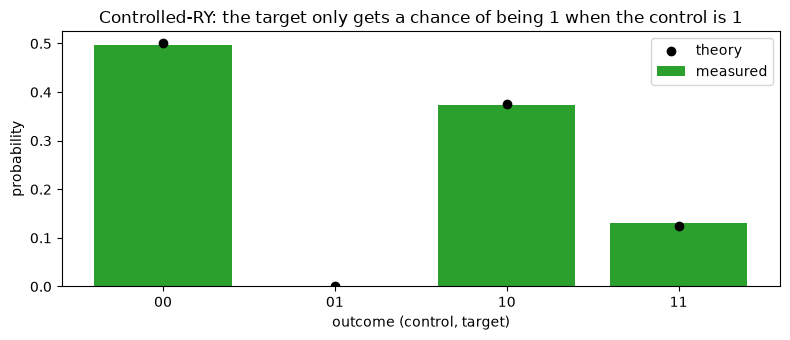


Bell circuit:
     ╭───╮     
q0 : ┤ h ├──●──
     ╰───╯╭─┴─╮
q1 : ─────┤ x ├
          ╰───╯

Step by step:
  Start          +1.000|00>
  After H on q0  +0.707|00>  +0.707|10>
  After CNOT     +0.707|00>  +0.707|11>
  Measured       {'00': 513, '11': 487}


In [3]:
#Introduction to quantum gates and quantum circuits
# Uses the Bloch sphere helpers and the bell() kernel from the Part 2 cell: run that cell first.


def show_state(state):
    """Write a state as amplitudes, e.g. 0.707|00> + 0.707|11> (skipping zeros)."""
    amps = np.array(state)
    n = int(np.log2(len(amps)))
    terms = []
    for i, amp in enumerate(amps):
        if abs(amp) > 1e-6:
            label = "".join(str((i >> k) & 1) for k in range(n))   # qubit 0 written first
            terms.append(f"{amp.real:+.3f}|{label}>")
    return "  ".join(terms)


# --- 3.2 Single-qubit gates on the Bloch sphere ------------------------------

@cudaq.kernel
def apply_x():
    q = cudaq.qubit()
    x(q)

@cudaq.kernel
def apply_h():
    q = cudaq.qubit()
    h(q)

@cudaq.kernel
def apply_h_then_z():
    q = cudaq.qubit()
    h(q)
    z(q)                   # flips the sign of beta

@cudaq.kernel
def apply_ry(theta: float):
    q = cudaq.qubit()
    ry(theta, q)


single_gates = [
    ("X",        apply_x,        ()),
    ("H",        apply_h,        ()),
    ("H then Z", apply_h_then_z, ()),
    ("RY(60°)",  apply_ry,       (np.radians(60),)),
]

print("Single-qubit gates, each starting from |0>")
print(f"{'Gate':<10}{'alpha':>8}{'beta':>8}{'P(0)':>7}{'P(1)':>7}{'measured 0 / 1':>17}")

fig = plt.figure(figsize=(14, 4))
for i, (name, kernel, args) in enumerate(single_gates):
    state = cudaq.get_state(kernel, *args)
    alpha, beta = np.array(state)
    counts = cudaq.sample(kernel, *args, shots_count=SHOTS)

    print(f"{name:<10}{alpha.real:>8.3f}{beta.real:>8.3f}{abs(alpha)**2:>7.0%}{abs(beta)**2:>7.0%}"
          f"{counts.count('0'):>10} / {counts.count('1')}")

    ax = fig.add_subplot(1, len(single_gates), i + 1, projection="3d")
    draw_bloch(ax, qubit_on_its_own(state, 0), f"{name}\nP(1) = {abs(beta)**2:.0%}")

fig.suptitle("Every gate is a rotation. H and 'H then Z' point opposite ways but have the same odds: "
             "the difference is phase", y=1.05)
plt.tight_layout()
plt.show()


# --- 3.3 / 3.4 Undoing gates and interference ---------------------------------

@cudaq.kernel
def x_x():
    q = cudaq.qubit()
    x(q)
    x(q)

@cudaq.kernel
def h_h():
    q = cudaq.qubit()
    h(q)
    h(q)

@cudaq.kernel
def h_z_h():
    q = cudaq.qubit()
    h(q)
    z(q)
    h(q)


sequences = [("H", apply_h), ("X, X", x_x), ("H, H", h_h), ("H, Z, H", h_z_h)]

print("\nSequences of gates, each starting from |0>")
print(f"{'Sequence':<10}{'final state':<26}{'measured 0 / 1':>15}")

zeros, ones = [], []
for name, kernel in sequences:
    counts = cudaq.sample(kernel, shots_count=SHOTS)
    zeros.append(counts.count("0"))
    ones.append(counts.count("1"))
    print(f"{name:<10}{show_state(cudaq.get_state(kernel)):<26}{zeros[-1]:>8} / {ones[-1]}")

labels = [name for name, _ in sequences]
positions = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(positions - 0.2, zeros, width=0.4, label="measured 0", color="tab:blue")
ax.bar(positions + 0.2, ones, width=0.4, label="measured 1", color="tab:orange")
ax.set_xticks(positions, labels)
ax.set_ylabel(f"count out of {SHOTS}")
ax.set_title("X, X and H, H undo themselves. Adding Z in the middle flips the answer: interference")
ax.legend()
plt.tight_layout()
plt.show()


# --- 3.5 The controlled-RY ----------------------------------------------------

@cudaq.kernel
def controlled_ry(theta: float):
    q = cudaq.qvector(2)
    h(q[0])                        # control: an equal blend of 0 and 1
    ry.ctrl(theta, q[0], q[1])     # rotate the target only when the control is 1


theta = np.radians(60)             # RY(60°) gives P(1) = sin²(30°) = 25%
counts = cudaq.sample(controlled_ry, theta, shots_count=SHOTS)

print("\nControlled-RY(60°) circuit:")
print(cudaq.draw(controlled_ry, theta))
print(f"{'Outcome':<9}{'theory':>8}{'measured':>10}")
theory = {"00": 0.5, "01": 0.0, "10": 0.5 * np.cos(theta / 2)**2, "11": 0.5 * np.sin(theta / 2)**2}
for outcome, p in theory.items():
    print(f"  {outcome:<7}{p:>8.1%}{counts.count(outcome) / SHOTS:>10.1%}")

control_was_1 = counts.count("10") + counts.count("11")
print(f"\nWhen the control is 0, the target is never 1 (count of 01 = {counts.count('01')}).")
print(f"When the control is 1, the target is 1 in {counts.count('11') / control_was_1:.0%} of cases "
      f"(theory {np.sin(theta / 2)**2:.0%}).")

fig, ax = plt.subplots(figsize=(8, 3.5))
outcomes = list(theory)
ax.bar(outcomes, [counts.count(o) / SHOTS for o in outcomes], color="tab:green", label="measured")
ax.scatter(outcomes, list(theory.values()), color="black", zorder=3, label="theory")
ax.set_xlabel("outcome (control, target)")
ax.set_ylabel("probability")
ax.set_title("Controlled-RY: the target only gets a chance of being 1 when the control is 1")
ax.legend()
plt.tight_layout()
plt.show()


# --- 3.6 Reading a circuit step by step -------------------------------------

@cudaq.kernel
def bell_up_to(steps: int):
    q = cudaq.qvector(2)
    if steps >= 1:
        h(q[0])
    if steps >= 2:
        x.ctrl(q[0], q[1])


print("\nBell circuit:")
print(cudaq.draw(bell))
print("Step by step:")
for steps, description in enumerate(["Start", "After H on q0", "After CNOT"]):
    print(f"  {description:<15}{show_state(cudaq.get_state(bell_up_to, steps))}")
print(f"  {'Measured':<15}{dict(cudaq.sample(bell, shots_count=SHOTS).items())}")


# Part 4: The Bernoulli Random Variable

## 4.1 What is a Bernoulli variable?

A **Bernoulli random variable** is the simplest random quantity there is: a yes/no outcome. It equals `1` with probability $p$ and `0` otherwise, like a coin that lands heads with probability $p$.

$$
X \in \{0, 1\}, \qquad P(X = 1) = p, \qquad P(X = 0) = 1 - p
$$

Its average (expected value) is simply $p$, and its variance measures how uncertain the outcome is:

$$
\mathbb{E}[X] = p, \qquad \text{Var}(X) = p\,(1 - p)
$$

The variance is largest at $p = 50\%$, when the outcome is hardest to predict, and zero at $p = 0$ or $p = 1$, when the outcome is certain.

## 4.2 A rebate example

Part 1 showed that reaching a new tier triggers a **true-up**: all earlier spend is re-rated at the higher rate. Whether a customer reaches Tier 3 by year end is a Bernoulli variable:

$$
X = \begin{cases} 1 & \text{customer reaches 25,000 units (true-up paid)} \\ 0 & \text{customer stays in Tier 2} \end{cases}
$$

Suppose the customer is forecast at about £1.5m of spend, so reaching Tier 3 triggers a true-up of $2\% \times £1.5\text{m} = £30{,}000$. Suppose also that the customer has a **30% chance** of getting there. The supplier's **expected true-up cost** is then

$$
\mathbb{E}[\text{cost}] = p \times £30{,}000 = 0.30 \times £30{,}000 = £9{,}000
$$

This is the basic building block of rebate liability: a *probability* of reaching a tier multiplied by the *cost* of paying it. The hard part in practice is knowing $p$.

## 4.3 Loading a probability into a qubit

A qubit is a natural home for a Bernoulli variable. From Part 3, the RY gate tilts the arrow so that $P(1) = \sin^2(\theta/2)$. To load a chosen probability $p$, pick the angle

$$
\theta = 2\arcsin\sqrt{p}
$$

The qubit is then in the state

$$
|\psi\rangle = \sqrt{1 - p}\;|0\rangle + \sqrt{p}\;|1\rangle
$$

**Measuring the qubit is one Bernoulli trial.** It gives `1` with probability $p$ and `0` otherwise. For $p = 30\%$, the angle is $\theta \approx 66.4°$ and the state is $0.837\,|0\rangle + 0.548\,|1\rangle$.

On the Bloch sphere, the higher $p$ is, the further the arrow tilts towards $|1\rangle$ at the south pole.

## 4.4 Estimating p by measuring

If $p$ is unknown, the obvious way to estimate it is to prepare and measure the qubit $N$ times and count the `1`s:

$$
\hat{p} = \frac{\text{number of 1s}}{N}
$$

This is exactly how classical **Monte Carlo simulation** works: run many random scenarios and count. The estimate improves with more shots, but slowly. Its typical error (the standard error) is

$$
\text{error} \approx \sqrt{\frac{p\,(1 - p)}{N}}
$$

For $p = 30\%$:

| Shots $N$ | Typical error in $\hat{p}$ | Typical error in the £9,000 cost |
|---|---|---|
| 100 | ± 4.6% | ± £1,370 |
| 1,000 | ± 1.4% | ± £430 |
| 10,000 | ± 0.46% | ± £140 |

The error shrinks like $1/\sqrt{N}$, so **10× more accuracy costs 100× more shots**. For a real portfolio with thousands of customers, many tiers and uncertain volumes, this becomes expensive quickly.

This limit is the target for **quantum amplitude estimation**, which uses the interference ideas from Part 3 to reach an error that shrinks like $1/N$. For the same accuracy, it needs roughly the *square root* of the number of shots.

## 4.5 Several customers

Each customer can be given their own qubit, loaded with their own probability. With three customers there are $2^3 = 8$ possible scenarios of who reaches Tier 3, and a single measurement of all three qubits samples one of them.

| Customer | P(reaches Tier 3) | True-up if reached | Expected cost |
|---|---|---|---|
| A | 30% | £30,000 | £9,000 |
| B | 60% | £12,000 | £7,200 |
| C | 10% | £50,000 | £5,000 |
| **Portfolio** | | | **£21,200** |

Here each customer is independent. The real value of qubits appears when outcomes are **linked**, for example when customers in the same market tend to grow together. Those links can be built in with the controlled gates from Part 3, which makes the scenarios much harder to enumerate classically.

## Summary

| Idea | In plain terms |
|---|---|
| Bernoulli variable | A yes/no outcome that is `1` with probability $p$ |
| Expected value | The average outcome, equal to $p$ |
| Rebate meaning | $p$ is the chance of reaching a tier; $p \times$ true-up is the expected cost |
| Loading into a qubit | RY with $\theta = 2\arcsin\sqrt{p}$ gives $\sqrt{1-p}\,\lvert 0\rangle + \sqrt{p}\,\lvert 1\rangle$ |
| Measuring | One Bernoulli trial per shot |
| Estimating by sampling | Error shrinks like $1/\sqrt{N}$, so 100× the shots for 10× the accuracy |
| Several customers | One qubit each; $n$ customers give $2^n$ scenarios |

Loading p = 30% into a qubit
  angle θ = 2·arcsin(√p) = 66.4°
  state   = 0.837|0> + 0.548|1>
  P(1)    = 30.0%
  Expected true-up cost = p × £30,000 = £9,000


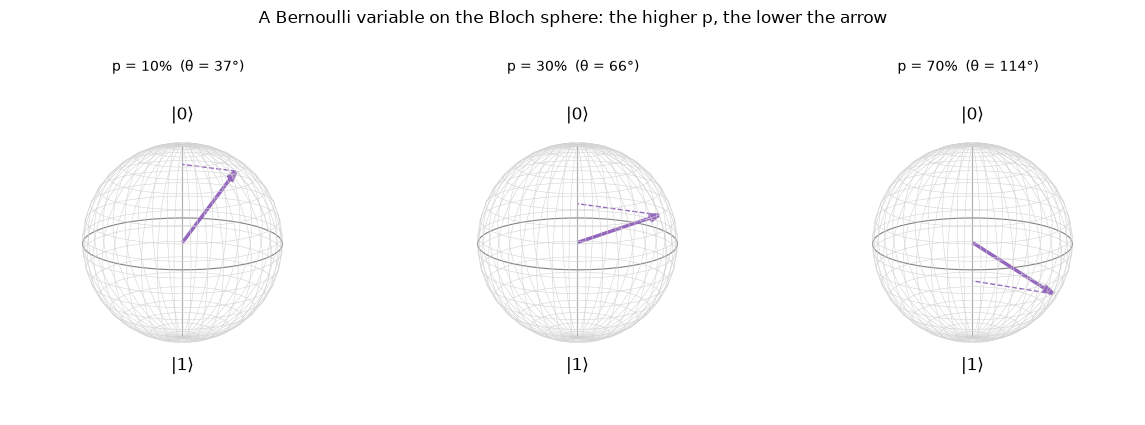


Estimating p = 30% by measuring (20 repeats per row)
   Shots  typical error   theory √(p(1-p)/N)      cost estimate range
     100          4.69%                4.58%         £7,200 – £12,300
   1,000          1.24%                1.45%          £8,490 – £9,870
  10,000          0.49%                0.46%          £8,655 – £9,177
10× more accuracy needs 100× more shots.


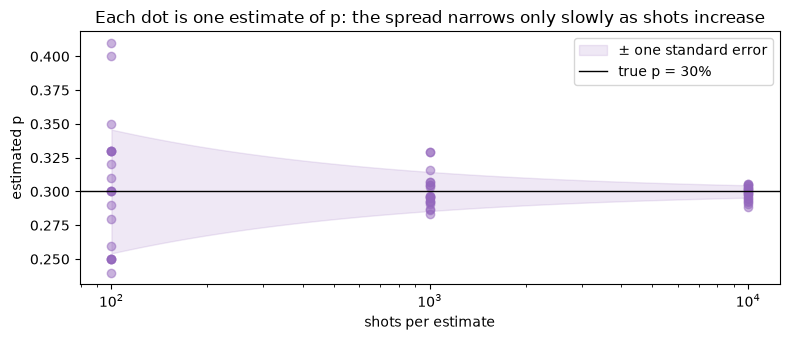


Three customers, 1000 measured scenarios (1 = reaches Tier 3)
A B C    count  true-up cost
0 1 0      387       £12,000
0 0 0      231            £0
1 1 0      147       £42,000
1 0 0      123       £30,000
0 1 1       43       £62,000
0 0 1       33       £50,000
1 1 1       23       £92,000
1 0 1       13       £80,000

Expected true-up cost: estimated £21,980, exact £21,200


In [4]:
#Introduction to Bernoulli vairable
# Uses the Bloch sphere helpers from the Part 2 cell: run that cell first.


def bernoulli_angle(p):
    """RY angle that loads probability p into a qubit: P(1) = sin²(θ/2) = p."""
    return 2 * np.arcsin(np.sqrt(p))


@cudaq.kernel
def bernoulli(theta: float):
    q = cudaq.qubit()
    ry(theta, q)          # the qubit is now 1 with probability p


# --- 4.3 Loading a probability into a qubit ----------------------------------

TRUE_UP = 30_000          # £ extra rebate if the customer reaches Tier 3 (2% × £1.5m)
p = 0.30                  # chance the customer reaches Tier 3

theta = bernoulli_angle(p)
alpha, beta = np.array(cudaq.get_state(bernoulli, theta))

print(f"Loading p = {p:.0%} into a qubit")
print(f"  angle θ = 2·arcsin(√p) = {np.degrees(theta):.1f}°")
print(f"  state   = {alpha.real:.3f}|0> + {beta.real:.3f}|1>")
print(f"  P(1)    = {abs(beta)**2:.1%}")
print(f"  Expected true-up cost = p × £{TRUE_UP:,} = £{p * TRUE_UP:,.0f}")

fig = plt.figure(figsize=(12, 4))
for i, prob in enumerate([0.10, 0.30, 0.70]):
    state = cudaq.get_state(bernoulli, bernoulli_angle(prob))
    ax = fig.add_subplot(1, 3, i + 1, projection="3d")
    draw_bloch(ax, qubit_on_its_own(state, 0),
               f"p = {prob:.0%}  (θ = {np.degrees(bernoulli_angle(prob)):.0f}°)", "tab:purple")
fig.suptitle("A Bernoulli variable on the Bloch sphere: the higher p, the lower the arrow", y=1.05)
plt.tight_layout()
plt.show()


# --- 4.4 Estimating p by measuring --------------------------------------------

shot_counts = [100, 1_000, 10_000]
REPEATS = 20              # repeat each experiment to see how much the estimate varies

print(f"\nEstimating p = {p:.0%} by measuring ({REPEATS} repeats per row)")
print(f"{'Shots':>8}{'typical error':>15}{'theory √(p(1-p)/N)':>21}{'cost estimate range':>25}")

estimates = {}
for shots in shot_counts:
    runs = [cudaq.sample(bernoulli, theta, shots_count=shots).count("1") / shots
            for _ in range(REPEATS)]
    estimates[shots] = runs
    typical_error = np.std(runs)
    theory_error = np.sqrt(p * (1 - p) / shots)
    low, high = min(runs) * TRUE_UP, max(runs) * TRUE_UP
    print(f"{shots:>8,}{typical_error:>15.2%}{theory_error:>21.2%}"
          f"{f'£{low:,.0f} – £{high:,.0f}':>25}")

print("10× more accuracy needs 100× more shots.")

fig, ax = plt.subplots(figsize=(8, 3.5))
for shots, runs in estimates.items():
    ax.scatter([shots] * len(runs), runs, color="tab:purple", alpha=0.5)
n = np.logspace(2, 4, 100)
band = np.sqrt(p * (1 - p) / n)
ax.fill_between(n, p - band, p + band, color="tab:purple", alpha=0.15, label="± one standard error")
ax.axhline(p, color="black", linewidth=1, label=f"true p = {p:.0%}")
ax.set_xscale("log")
ax.set_xlabel("shots per estimate")
ax.set_ylabel("estimated p")
ax.set_title("Each dot is one estimate of p: the spread narrows only slowly as shots increase")
ax.legend()
plt.tight_layout()
plt.show()


# --- 4.5 Several customers ------------------------------------------------------

@cudaq.kernel
def portfolio(thetas: list[float]):
    q = cudaq.qvector(len(thetas))         # one qubit per customer
    for i in range(len(thetas)):
        ry(thetas[i], q[i])                # load each customer's probability


customers = ["A", "B", "C"]
probs = [0.30, 0.60, 0.10]                  # chance each customer reaches Tier 3
true_ups = [30_000, 12_000, 50_000]         # £ true-up each would trigger

counts = cudaq.sample(portfolio, [bernoulli_angle(pr) for pr in probs], shots_count=SHOTS)

print(f"\nThree customers, {SHOTS} measured scenarios (1 = reaches Tier 3)")
print(f"{'A B C':<8}{'count':>6}{'true-up cost':>14}")
estimated_cost = 0
for bits, count in sorted(counts.items(), key=lambda item: -item[1]):
    cost = sum(int(b) * c for b, c in zip(bits, true_ups))
    estimated_cost += cost * count / SHOTS
    print(f"{' '.join(bits):<8}{count:>6}{f'£{cost:,}':>14}")

exact_cost = sum(pr * c for pr, c in zip(probs, true_ups))
print(f"\nExpected true-up cost: estimated £{estimated_cost:,.0f}, exact £{exact_cost:,.0f}")


# Part 5: The Grover Operator

## 5.1 The idea: amplifying the outcome we care about

Part 4 loaded a probability into a qubit: measuring it gives the **"good"** outcome (`1`, the customer reaches Tier 3) with probability $p$. When $p$ is small, that outcome rarely appears, so learning anything about it takes many shots.

The **Grover operator** $Q$ is a fixed sequence of gates that makes the good outcome **more likely each time it is applied**. It does this by using interference (Part 3.4): the amplitude of the good outcome builds up, and the amplitude of the bad outcomes cancels away. This is called **amplitude amplification**.

## 5.2 Building the Grover operator

Call the circuit that loads the probabilities $A$. In Part 4, $A$ is a single RY gate. The prepared state splits into a good part and a bad part:

$$
A\,|0\rangle = \sqrt{1-p}\;|\text{bad}\rangle + \sqrt{p}\;|\text{good}\rangle
$$

The Grover operator is made of **two reflections**:

1. **Mark the good outcome.** Flip the sign of $|\text{good}\rangle$ and leave $|\text{bad}\rangle$ alone. This is exactly what the Z gate did in the H, Z, H example from Part 3.4. The odds don't change, only the hidden sign.
2. **Reflect about the starting state.** Undo the preparation ($A^\dagger$), flip the sign of $|0\rangle$, then redo the preparation ($A$).

$$
Q = \underbrace{A \, S_0 \, A^\dagger}_{\text{reflect about the start}} \; \underbrace{S_{\text{good}}}_{\text{mark good}}
$$

Neither reflection changes the probabilities on its own. **Together, they make a rotation**, and that is the whole trick.

## 5.3 The picture: a rotation

Every state of the form above sits on a quarter circle, with "bad" along one axis and "good" along the other. Write the starting point as an angle $\theta_p$ from the bad axis:

$$
A\,|0\rangle = \cos\theta_p\,|\text{bad}\rangle + \sin\theta_p\,|\text{good}\rangle, \qquad p = \sin^2\theta_p
$$

(This $\theta_p$ is half of the RY angle from Part 4.)

**Each Grover step rotates the state by $2\theta_p$ towards "good".** After $k$ steps, the angle is $(2k+1)\,\theta_p$, so

$$
P(\text{good after } k \text{ steps}) = \sin^2\!\big((2k+1)\,\theta_p\big)
$$

## 5.4 A worked example

For a customer with a $p = 10\%$ chance of reaching Tier 3, $\theta_p = \arcsin\sqrt{0.1} \approx 18.4°$, so each step rotates the state by about $36.9°$:

| Steps $k$ | Angle $(2k+1)\,\theta_p$ | P(good) |
|---|---|---|
| 0 | 18.4° | 10.0% |
| 1 | 55.3° | 67.6% |
| 2 | 92.2° | 99.9% |
| 3 | 129.0° | 60.3% |
| 4 | 165.9° | 5.9% |

**After two steps, a 10% outcome has become almost certain.** Past that point, the rotation **overshoots** the good axis and the probability falls again. P(good) rises and falls in a regular wave as $k$ increases.

## 5.5 Several customers

The same recipe works on any number of qubits. With two customers A (30%) and B (60%), define "good" as the scenario where **both** reach Tier 3, which has probability $0.3 \times 0.6 = 18\%$.

- **Marking** now uses a controlled-Z, which flips the sign of $|11\rangle$ only.
- **Reflecting about the start** undoes both RY gates, flips the sign of $|00\rangle$, and redoes them.

One Grover step lifts the "both reach Tier 3" scenario from 18% to about 94%.

For a single qubit, $Q$ works out to be just a larger RY rotation. **The value of Grover shows on bigger circuits:** when $A$ models a whole portfolio with linked customers, nobody can write down $p$ directly, yet $Q$ still rotates by exactly $2\theta_p$.

## 5.6 Two uses of the Grover operator

The rotation can be used in two ways:

| Use | What it does | Rebate question it answers |
|---|---|---|
| **Grover search** | Apply $Q$ until the good outcome is nearly certain, about $\tfrac{\pi}{4\sqrt{p}}$ steps, then measure | *Find* a scenario or design that meets a condition |
| **Amplitude estimation** | Measure *how fast* $Q$ rotates the state, then read off $\theta_p$ and so $p$ | *Estimate* the probability of reaching a tier, or the expected rebate cost |

The rise-and-fall wave from 5.4 is the key to the second use. **Its speed depends only on $p$**: a larger $p$ gives a faster wave. Amplitude estimation measures that speed very precisely, which is why it can estimate $p$ with error shrinking like $1/N$ rather than the $1/\sqrt{N}$ of simple sampling from Part 4.

## Summary

| Idea | In plain terms |
|---|---|
| Amplitude amplification | Make a rare "good" outcome more likely, using interference |
| Mark | Flip the sign of the good outcome (Z, or controlled-Z for scenarios) |
| Reflect about the start | Undo $A$, flip the sign of $\lvert 0\rangle$, redo $A$ |
| Grover operator $Q$ | Mark, then reflect: together a rotation by $2\theta_p$ |
| After $k$ steps | P(good) $= \sin^2((2k+1)\,\theta_p)$, rising, then overshooting |
| Grover search | Stop at the peak to find the good outcome |
| Amplitude estimation | Measure the speed of the wave to estimate $p$ |

One Grover step, drawn as a circuit:
     ╭────────────╮╭───╮╭─────────────╮╭───╮╭───╮╭───╮╭────────────╮
q0 : ┤ ry(0.6435) ├┤ z ├┤ ry(-0.6435) ├┤ x ├┤ z ├┤ x ├┤ ry(0.6435) ├
     ╰────────────╯╰───╯╰─────────────╯╰───╯╰───╯╰───╯╰────────────╯

p = 10%,  θp = 18.4°,  each step rotates by 2θp = 36.9°

 Steps k  angle (2k+1)θp  P(good) theory  P(good) measured
       0           18.4°           10.0%             10.9%
       1           55.3°           67.6%             65.1%
       2           92.2°           99.9%             99.8%
       3          129.0°           60.3%             63.9%
       4          165.9°            5.9%              6.7%
       5          202.8°           15.0%             15.3%
P(good) rises to almost 100% after 2 steps, then overshoots and falls again.


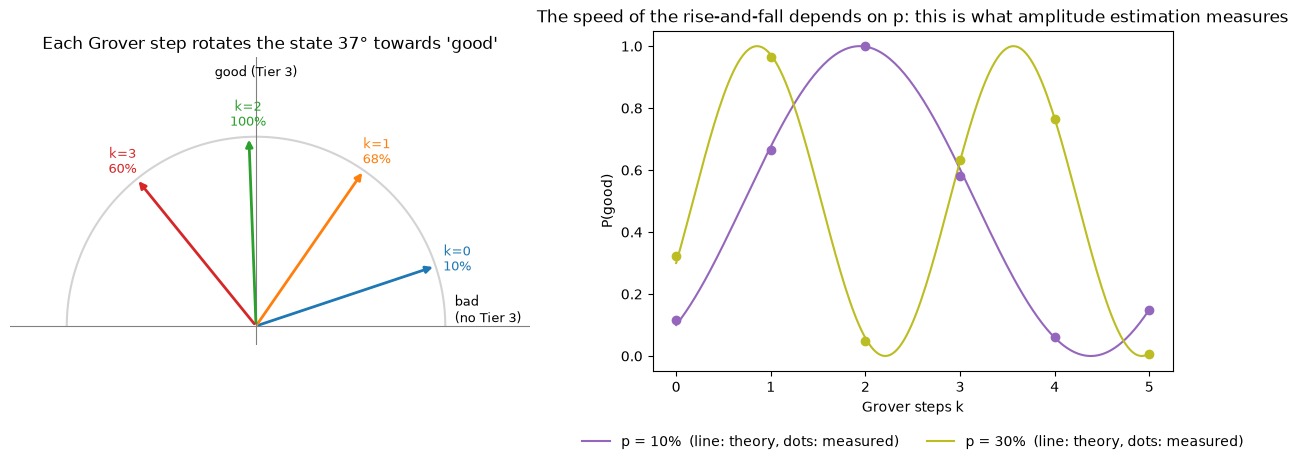


Two customers: P(A reaches Tier 3) = 30%, P(B reaches Tier 3) = 60%
'Good' scenario = both reach Tier 3, with p = 18%

k = 0:  00:  296  01:  425  10:  107  11:  172   theory P(11) = 18.0%
k = 1:  00:   23  01:   37  10:   11  11:  929   theory P(11) = 93.6%


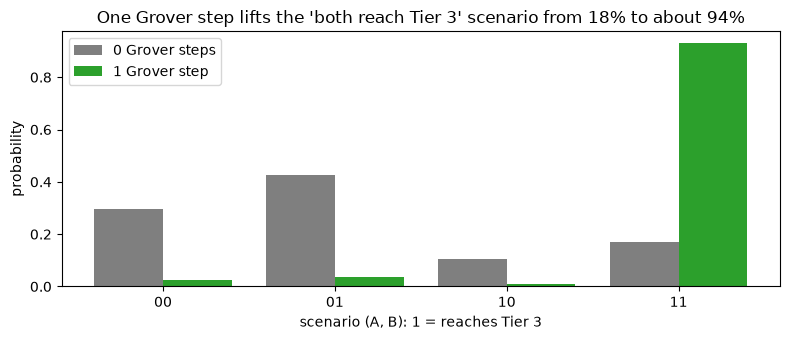

In [5]:
#Introduction to Grover operator
# Uses bernoulli_angle() from the Part 4 cell: run the Part 2 and Part 4 cells first.


# --- 5.2 / 5.6 The Grover operator for one customer --------------------------

@cudaq.kernel
def grover_one(theta: float, k: int):
    q = cudaq.qubit()
    ry(theta, q)              # A: load p (the "good" outcome is 1)
    for i in range(k):        # apply the Grover operator Q, k times
        z(q)                  #   1. mark the good outcome by flipping its sign
        ry(-theta, q)         #   2. undo A ...
        x(q)
        z(q)                  #      ... reflect about the starting point |0> ...
        x(q)
        ry(theta, q)          #      ... and redo A


p = 0.10                                   # chance the customer reaches Tier 3
theta = bernoulli_angle(p)                 # RY angle from Part 4
theta_p = np.arcsin(np.sqrt(p))            # angle in the good/bad plane: p = sin²(θp)

print("One Grover step, drawn as a circuit:")
print(cudaq.draw(grover_one, theta, 1))

print(f"p = {p:.0%},  θp = {np.degrees(theta_p):.1f}°,  each step rotates by 2θp = {np.degrees(2 * theta_p):.1f}°\n")
print(f"{'Steps k':>8}{'angle (2k+1)θp':>16}{'P(good) theory':>16}{'P(good) measured':>18}")

steps = range(6)
measured = []
for k in steps:
    counts = cudaq.sample(grover_one, theta, k, shots_count=SHOTS)
    measured.append(counts.count("1") / SHOTS)
    angle = (2 * k + 1) * theta_p
    print(f"{k:>8}{np.degrees(angle):>15.1f}°{np.sin(angle)**2:>16.1%}{measured[-1]:>18.1%}")

print("P(good) rises to almost 100% after 2 steps, then overshoots and falls again.")


# --- 5.3 The picture: a rotation in the good/bad plane -----------------------

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))

t = np.linspace(0, np.pi, 200)
ax1.plot(np.cos(t), np.sin(t), color="lightgrey")
ax1.axhline(0, color="grey", linewidth=0.8)
ax1.axvline(0, color="grey", linewidth=0.8)
ax1.text(1.05, 0.02, "bad\n(no Tier 3)", fontsize=9)
ax1.text(0, 1.32, "good (Tier 3)", ha="center", fontsize=9)

for k, colour in zip(range(4), ["tab:blue", "tab:orange", "tab:green", "tab:red"]):
    angle = (2 * k + 1) * theta_p
    ax1.annotate("", xy=(np.cos(angle), np.sin(angle)), xytext=(0, 0),
                 arrowprops=dict(arrowstyle="-|>", color=colour, linewidth=2))
    ax1.text(1.12 * np.cos(angle), 1.12 * np.sin(angle), f"k={k}\n{np.sin(angle)**2:.0%}",
             color=colour, ha="center", va="center", fontsize=9)

ax1.set_xlim(-1.3, 1.45); ax1.set_ylim(-0.1, 1.42)
ax1.set_aspect("equal"); ax1.axis("off")
ax1.set_title(f"Each Grover step rotates the state {np.degrees(2 * theta_p):.0f}° towards 'good'")

# How P(good) rises and falls with k, for two different starting probabilities
k_smooth = np.linspace(0, 5, 200)
for prob, colour in [(0.10, "tab:purple"), (0.30, "tab:olive")]:
    tp = np.arcsin(np.sqrt(prob))
    ax2.plot(k_smooth, np.sin((2 * k_smooth + 1) * tp)**2, color=colour, label=f"p = {prob:.0%}  (line: theory, dots: measured)")
    points = [cudaq.sample(grover_one, bernoulli_angle(prob), k, shots_count=SHOTS).count("1") / SHOTS
              for k in steps]
    ax2.scatter(list(steps), points, color=colour, zorder=3)

ax2.set_xlabel("Grover steps k")
ax2.set_ylabel("P(good)")
ax2.set_title("The speed of the rise-and-fall depends on p: this is what amplitude estimation measures")
ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False)
plt.tight_layout()
plt.show()


# --- 5.5 Two customers: amplify "both reach Tier 3" ---------------------------

@cudaq.kernel
def grover_two(theta_a: float, theta_b: float, k: int):
    q = cudaq.qvector(2)
    ry(theta_a, q[0])          # A: load each customer's probability
    ry(theta_b, q[1])
    for i in range(k):
        z.ctrl(q[0], q[1])     #   1. mark the good scenario |11> (both reach Tier 3)
        ry(-theta_b, q[1])     #   2. undo A ...
        ry(-theta_a, q[0])
        x(q[0])
        x(q[1])
        z.ctrl(q[0], q[1])     #      ... reflect about the starting point |00> ...
        x(q[0])
        x(q[1])
        ry(theta_a, q[0])      #      ... and redo A
        ry(theta_b, q[1])


p_a, p_b = 0.30, 0.60
p_both = p_a * p_b
angles = (bernoulli_angle(p_a), bernoulli_angle(p_b))
tp_both = np.arcsin(np.sqrt(p_both))

print(f"\nTwo customers: P(A reaches Tier 3) = {p_a:.0%}, P(B reaches Tier 3) = {p_b:.0%}")
print(f"'Good' scenario = both reach Tier 3, with p = {p_both:.0%}\n")

outcomes = ["00", "01", "10", "11"]
fig, ax = plt.subplots(figsize=(8, 3.5))
for k, offset, colour in [(0, -0.2, "tab:grey"), (1, 0.2, "tab:green")]:
    counts = cudaq.sample(grover_two, *angles, k, shots_count=SHOTS)
    print(f"k = {k}:  " + "  ".join(f"{o}: {counts.count(o):>4}" for o in outcomes)
          + f"   theory P(11) = {np.sin((2 * k + 1) * tp_both)**2:.1%}")
    ax.bar(np.arange(4) + offset, [counts.count(o) / SHOTS for o in outcomes], width=0.4,
           color=colour, label=f"{k} Grover step{'s' if k != 1 else ''}")

ax.set_xticks(range(4), outcomes)
ax.set_xlabel("scenario (A, B): 1 = reaches Tier 3")
ax.set_ylabel("probability")
ax.set_title("One Grover step lifts the 'both reach Tier 3' scenario from 18% to about 94%")
ax.legend()
plt.tight_layout()
plt.show()


# Part 6: Quantum Amplitude Estimation

## 6.1 The goal

Part 4 showed that estimating a probability $p$ by repeated sampling is slow. With $N$ runs of the model, the error shrinks only like $1/\sqrt{N}$, so **10× more accuracy costs 100× more runs**. This is also the limit of classical Monte Carlo simulation.

**Quantum amplitude estimation (QAE)** estimates the same $p$ with error that shrinks like $1/N$: **10× more accuracy costs only about 10× more runs.** In rebate terms, $p$ could be the chance that a customer reaches Tier 3, and so the expected true-up cost.

## 6.2 The key idea: measure the rotation, not the coin

Part 5 showed that each Grover step rotates the state by a fixed angle $2\theta_p$, where $p = \sin^2\theta_p$. After $k$ steps:

$$
P(\text{good after } k \text{ steps}) = \sin^2\!\big((2k+1)\,\theta_p\big)
$$

Simple sampling measures the state only at $k = 0$, where the result depends on $\theta_p$ only weakly. QAE measures it **after many Grover steps as well**. There the angle has been multiplied by $(2k+1)$, so even a tiny change in $p$ makes a large, easily measured change in the result.

**An analogy:** to measure how fast a clock hand turns, you get a far more precise answer by watching it for 100 turns than for a fraction of one. Each Grover step is one more "turn".

## 6.3 How the estimate is made

This notebook uses a simple version of QAE called **maximum-likelihood amplitude estimation**:

1. **Run in rounds.** In each round, apply $k$ Grover steps and measure, repeated for a fixed number of shots. The number of steps doubles from round to round: $k = 0, 1, 2, 4, 8, 16, 32$.
2. **Record the hits.** For each round, count how many shots gave the good outcome.
3. **Find the best fit.** For every candidate value of $\theta_p$, work out how likely the recorded hits would be, using the formula above. The best estimate is the value that explains all the rounds best:

$$
\hat{\theta}_p = \arg\max_{\theta} \; \sum_{k} \Big[\, h_k \log \sin^2\!\big((2k+1)\theta\big) + (n - h_k) \log \cos^2\!\big((2k+1)\theta\big) \Big], \qquad \hat{p} = \sin^2\hat{\theta}_p
$$

   Here $h_k$ is the number of hits after $k$ steps and $n$ is the number of shots per round.

The early rounds, with small $k$, give a rough answer with no ambiguity. The later rounds, with large $k$, sharpen it. Each round narrows the range of values of $p$ that fit the data.

The textbook version of QAE uses *quantum phase estimation* to read the rotation angle directly, but it needs much deeper circuits. The maximum-likelihood version gets the same $1/N$ behaviour from the Grover operator alone, which makes it easier to run and to follow.

## 6.4 Counting the cost fairly

The fair comparison is the number of times the **model circuit $A$** is run, because in a real problem $A$ is the expensive part: it models the customer portfolio.

- **Classical sampling:** each sample runs $A$ once.
- **QAE:** one Grover step contains $A$ twice ($A^\dagger$ and $A$), so a shot after $k$ steps runs $A$ a total of $2k + 1$ times.

With 100 shots per round and rounds up to $k = 32$, QAE uses 13,300 model runs in total. Given the same 13,300 runs, classical sampling reaches a typical error of about ±0.4% in $p$, while QAE reaches about ±0.05%. That is around **6–7× more accurate for the same effort**, and the gap widens as the budget grows.

At small budgets there is **no advantage**: with only one or two rounds, QAE is no better than sampling, and can be slightly worse. The benefit comes from the large-$k$ rounds.

## 6.5 What this means for rebates, and the caveats

For a supplier, the quantities that matter are expected rebate costs across many customers, tiers and uncertain volumes. These are estimated today with Monte Carlo simulation. QAE offers a **quadratic reduction** in the number of scenario evaluations needed for a given accuracy. That matters most when each evaluation is expensive, or when many candidate tier structures need to be compared.

Some honest caveats:

- **The speed-up is in model runs, not wall-clock time on today's machines.** In this notebook everything runs on a classical simulator, which gains nothing.
- **Large $k$ means deep circuits.** Real hardware needs very low error rates (fault-tolerant quantum computers) before long Grover sequences give reliable results.
- **Estimating an expected cost,** not just a probability, needs the cost built into the circuit, usually as an extra qubit rotated in proportion to the payout. Part 7 builds on this.

## Summary

| Idea | In plain terms |
|---|---|
| Goal | Estimate a probability $p$ with fewer model runs than sampling |
| Key idea | Grover steps multiply the angle, making the result very sensitive to $p$ |
| Rounds | Measure after $k = 0, 1, 2, 4, \dots$ Grover steps |
| Maximum likelihood | Pick the $p$ that best explains every round's hits |
| Fair cost | Count calls to the model circuit $A$: $2k + 1$ per shot |
| Result | Error falls like $1/N$ rather than $1/\sqrt{N}$: a quadratic speed-up |
| Caveats | Needs deep, low-noise circuits; no speed-up on a classical simulator |

Estimating p = 30% with amplitude estimation (100 shots per round)

 Rounds         Grover steps used  model runs  estimate of p    error  cost estimate
      1                       [0]         100        37.000%   7.000%        £11,100
      2                    [0, 1]         400        30.038%   0.038%         £9,011
      3                 [0, 1, 2]         900        29.955%   0.045%         £8,986
      4              [0, 1, 2, 4]       1,800        29.695%   0.305%         £8,908
      5           [0, 1, 2, 4, 8]       3,500        29.951%   0.049%         £8,985
      6       [0, 1, 2, 4, 8, 16]       6,800        30.109%   0.109%         £9,033
      7   [0, 1, 2, 4, 8, 16, 32]      13,300        30.065%   0.065%         £9,019

True expected cost: £9,000


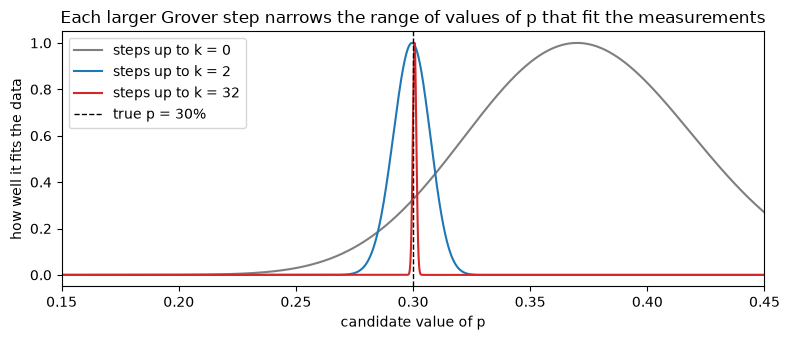


Typical error with the same number of model runs (50 repeats each)
 model runs  sampling (Part 4)  amplitude estimation  improvement
        100             4.441%                4.407%         1.0×
        400             1.935%                2.367%         0.8×
        900             1.464%                0.719%         2.0×
      1,800             0.950%                0.402%         2.4×
      3,500             0.795%                0.218%         3.6×
      6,800             0.471%                0.120%         3.9×
     13,300             0.383%                0.061%         6.3×


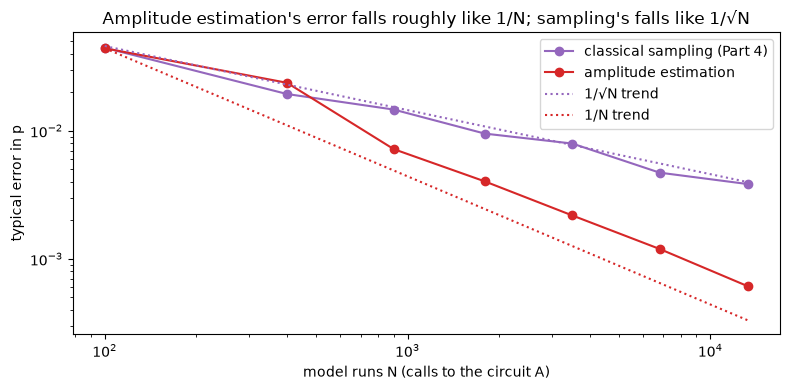

In [6]:
#Introduction to quantum amplitude estimation
# Uses bernoulli() and bernoulli_angle() from Part 4 and grover_one() from Part 5:
# run the Part 2, Part 4 and Part 5 cells first.


def likelihood_estimate(hits, shots_per_k, ks):
    """Maximum-likelihood QAE: the angle θp that best explains every measurement.

    hits[i] = number of 'good' results after ks[i] Grover steps.
    """
    grid = np.linspace(1e-6, np.pi / 2 - 1e-6, 200_001)          # candidate values of θp
    log_like = np.zeros_like(grid)
    for h, k in zip(hits, ks):
        p_good = np.sin((2 * k + 1) * grid) ** 2                 # 5.3: P(good after k steps)
        p_good = np.clip(p_good, 1e-12, 1 - 1e-12)
        log_like += h * np.log(p_good) + (shots_per_k - h) * np.log(1 - p_good)
    best = grid[np.argmax(log_like)]
    return np.sin(best) ** 2, grid, log_like


def model_runs(ks, shots_per_k):
    """Cost of an experiment: each shot after k steps runs the model A (2k + 1) times."""
    return shots_per_k * sum(2 * k + 1 for k in ks)


# --- 6.3 Estimating p = 30% ---------------------------------------------------

p = 0.30                       # true chance the customer reaches Tier 3 (unknown in practice)
TRUE_UP = 30_000               # £ true-up if they do (from Part 4)
theta = bernoulli_angle(p)

SCHEDULE = [0, 1, 2, 4, 8, 16, 32]   # Grover steps: double each time
SHOTS_PER_K = 100

hits = [cudaq.sample(grover_one, theta, k, shots_count=SHOTS_PER_K).count("1") for k in SCHEDULE]

print(f"Estimating p = {p:.0%} with amplitude estimation ({SHOTS_PER_K} shots per round)\n")
print(f"{'Rounds':>7}{'Grover steps used':>26}{'model runs':>12}{'estimate of p':>15}{'error':>9}"
      f"{'cost estimate':>15}")

curves = {}
for m in range(1, len(SCHEDULE) + 1):
    ks = SCHEDULE[:m]
    estimate, grid, log_like = likelihood_estimate(hits[:m], SHOTS_PER_K, ks)
    curves[m] = (grid, log_like)
    print(f"{m:>7}{str(ks):>26}{model_runs(ks, SHOTS_PER_K):>12,}{estimate:>15.3%}"
          f"{abs(estimate - p):>9.3%}{f'£{estimate * TRUE_UP:,.0f}':>15}")

print(f"\nTrue expected cost: £{p * TRUE_UP:,.0f}")


# --- The likelihood sharpens as larger Grover steps are added -----------------

fig, ax = plt.subplots(figsize=(8, 3.5))
for m, colour in [(1, "tab:grey"), (3, "tab:blue"), (7, "tab:red")]:
    grid, log_like = curves[m]
    like = np.exp(log_like - log_like.max())                     # scale so the peak is 1
    ax.plot(np.sin(grid) ** 2, like, color=colour,
            label=f"steps up to k = {SCHEDULE[m - 1]}")
ax.axvline(p, color="black", linestyle="--", linewidth=1, label=f"true p = {p:.0%}")
ax.set_xlim(0.15, 0.45)
ax.set_xlabel("candidate value of p")
ax.set_ylabel("how well it fits the data")
ax.set_title("Each larger Grover step narrows the range of values of p that fit the measurements")
ax.legend()
plt.tight_layout()
plt.show()


# --- 6.4 Quantum vs classical: error against the number of model runs ----------

REPEATS = 50
qae_runs, qae_errors, mc_errors = [], [], []

for m in range(1, len(SCHEDULE) + 1):
    ks = SCHEDULE[:m]
    budget = model_runs(ks, SHOTS_PER_K)
    qae_runs.append(budget)

    q_err, c_err = [], []
    for _ in range(REPEATS):
        h = [cudaq.sample(grover_one, theta, k, shots_count=SHOTS_PER_K).count("1") for k in ks]
        q_err.append(likelihood_estimate(h, SHOTS_PER_K, ks)[0] - p)

        # Classical sampling with the same budget: run the model once per sample (Part 4)
        c_hits = cudaq.sample(bernoulli, theta, shots_count=budget).count("1")
        c_err.append(c_hits / budget - p)

    qae_errors.append(np.sqrt(np.mean(np.square(q_err))))
    mc_errors.append(np.sqrt(np.mean(np.square(c_err))))

print(f"\nTypical error with the same number of model runs ({REPEATS} repeats each)")
print(f"{'model runs':>11}{'sampling (Part 4)':>19}{'amplitude estimation':>22}{'improvement':>13}")
for n, c, q in zip(qae_runs, mc_errors, qae_errors):
    print(f"{n:>11,}{c:>19.3%}{q:>22.3%}{c / q:>12.1f}×")

fig, ax = plt.subplots(figsize=(8, 4))
n = np.array(qae_runs)
ax.loglog(n, mc_errors, "o-", color="tab:purple", label="classical sampling (Part 4)")
ax.loglog(n, qae_errors, "o-", color="tab:red", label="amplitude estimation")
ax.loglog(n, np.sqrt(p * (1 - p) / n), ":", color="tab:purple", label="1/√N trend")
ax.loglog(n, qae_errors[0] * n[0] / n, ":", color="tab:red", label="1/N trend")
ax.set_xlabel("model runs N (calls to the circuit A)")
ax.set_ylabel("typical error in p")
ax.set_title("Amplitude estimation's error falls roughly like 1/N; sampling's falls like 1/√N")
ax.legend()
plt.tight_layout()
plt.show()


# Part 7: A New Quantum Approach to Constructing Rebate Programs

This Part brings the earlier pieces together into a method for **designing** a retroactive rebate program:

- **Part 1:** true-ups and the tier cliff.
- **Part 4:** Bernoulli variables loaded into qubits.
- **Part 5:** the Grover operator.
- **Part 6:** amplitude estimation.

The approach follows the quantum **credit risk analysis** model of Egger et al. (2021), which gives each borrower one qubit that measures `1` if they default. Here, each **customer** gets one qubit that measures `1` if they reach the top tier:

| Credit risk (Egger et al.) | Rebate program (this notebook) |
|---|---|
| A borrower | A customer |
| The borrower defaults | The customer reaches Tier 3 |
| Loss given default | The Tier 3 true-up paid to that customer |
| The economy affects all borrowers | A shared demand driver affects many customers' volumes |
| Total portfolio loss | Total Tier 3 true-ups paid this year |
| Value at risk: P(loss > limit) | **P(true-ups exceed the rebate budget)** |

The question the circuit answers: **for a given program design, what is the probability that total rebate payouts exceed the budget?** The design is then chosen to maximise how many valuable customers reach the top tier, while keeping that probability below a risk limit.

## 7.1 The rebate program and the design choices

The program has **three volume tiers** with **retroactive rates**: reaching a tier applies its rate to all purchases of the product in the year (Part 1). Tiers 1 and 2 are fixed, and the design chooses the top tier:

| Tier | Threshold | Retroactive rate |
|---|---|---|
| 1 | 2,000 units | 0.5% |
| 2 | 5,000 units | 1.5% |
| 3 | **8,000 or 12,000 units** | **3% or 5%** |

This gives four candidate designs. When a customer crosses the Tier 3 threshold, all their spend so far is re-rated from the Tier 2 rate to the Tier 3 rate. This is the **true-up**, the tier cliff from Part 1.3:

$$
\Delta R = (r_3 - r_2)\; p\; t_3
$$

With a unit price $p$ of £50, the Tier 3 design of 8,000 units at 5% gives $\Delta R = (0.05 - 0.015) \times £50 \times 8{,}000 = £14{,}000$ per customer.

The supplier sets aside a **budget of £90,000** for Tier 3 true-ups. A design is acceptable only if the chance of exceeding it is **at most 5%**.

## 7.2 One qubit per customer

Eight customers, grouped by lifetime value (LTV), each get their own qubit:

| Customer | LTV group | Typical annual units $\mu_i$ | LTV weight $w_i$ | Volume uplift per 1% of Tier 3 rate |
|---|---|---|---|---|
| L1, L2, L3 | Low | 5,000 / 5,500 / 6,000 | 1 | +3% |
| M1, M2, M3 | Mid | 7,000 / 7,500 / 8,000 | 2 | +5% |
| H1, H2 | High | 10,000 / 11,000 | 4 | +7% |

**Volume.** Each customer's annual volume $Q_i$ follows their own bell curve. A more generous Tier 3 rate is an incentive that shifts the curve up:

$$
Q_i \sim \text{Normal}\Big(\mu_i\,\big(1 + u_i \cdot 100\,r_3\big),\; 0.35\,\mu_i\Big)
$$

**The Bernoulli variable (Part 4).** Customer $i$ reaches Tier 3 with probability

$$
p_i = P\big(Q_i \ge t_3\big)
$$

and their qubit is loaded with $\theta_i = 2\arcsin\sqrt{p_i}$.

**The objective.** The supplier wants valuable customers to reach the top tier. The **LTV score** is the weighted expected share of customers who do:

$$
S = \frac{\sum_i w_i\, p_i}{\sum_i w_i}
$$

## 7.3 Linking customers through a common demand driver

**What $Z$ is.** $Z$ is a *latent variable*: an unobserved number that represents whatever makes customers' volumes come in above or below forecast **in the same year**. It isn't a market index, and customers don't "follow" it. It is a compact way to model co-movement, in the same way the credit risk model uses it to capture defaults that cluster together.

**The question $Z$ answers:** when one customer's volume comes in above or below forecast, do other customers' volumes tend to do the same? In B2B, shared drivers include:

- **End demand in their industry.** Distributors of building products all feel a slow construction season, and suppliers to car makers all feel production cuts.
- **Inventory cycles.** Customers stocking up or running stock down at the same time, as in the 2022–23 destocking in chemicals and electronics.
- **The supplier's own actions.** A list-price increase, supply allocation, a product discontinuation or longer lead times affect every customer at once.
- **Competitor moves.** A competitor's price cut or new product pulls volume from many customers together.
- **Seasonality and weather,** for example in agriculture, HVAC and building materials.

Equally, many B2B volume swings are **customer-specific**: winning or losing a contract, a plant opening, a merger, a change of buyer. The model separates the two. Each customer's outcome depends partly on the shared driver $Z$ and partly on their own circumstances. This is the *Gaussian conditional independence* model:

$$
P(\text{customer } i \text{ reaches Tier 3} \mid Z = z) = \Phi\!\left(\frac{\Phi^{-1}(p_i) + \sqrt{\rho}\; z}{\sqrt{1 - \rho}}\right)
$$

Here $\Phi$ is the standard normal distribution function, and $\rho$ is the share of each customer's volume surprise explained by the shared driver: $\rho = 0$ means fully independent customers. Averaged over $Z$, each customer still reaches Tier 3 with probability $p_i$, but **given** $Z$ their outcomes are linked.

**Calibrating $\rho$ from data.** $\rho$ should be estimated, not assumed:

1. Forecast each customer's annual volume and take the gap between forecast and actual.
2. Check whether those gaps move together across customers, period by period, using a simple correlation or principal component analysis.
3. If a common component explains a meaningful share, set $\rho$ to match it. That component often turns out to be an interpretable driver, such as an industry production index. If it explains little, set $\rho \approx 0$.

**In this notebook, $\rho = 0.3$ is an illustrative assumption, not an estimate.**

**In the circuit,** $Z$ is held in **two qubits** as four levels, from a weak year to a strong year for the shared driver ($z = -1.5, -0.5, 0.5, 1.5$), loaded with their normal-curve probabilities.

**Why this matters.** When customers share a driver, years where *many* of them reach Tier 3 at once become more likely. The distribution of the total gets **fatter tails**, and budget breaches become more likely than an independent model suggests.

**When one factor is enough.** A single $Z$ suits customers who share the same main driver, for example one industry or one channel. A portfolio spread across industries needs a **multi-factor** model: a global factor plus one factor per industry, so that customers in the same industry are more closely linked than customers in different ones. The circuit structure is the same, with one small register per factor.

## 7.4 Constructing the circuit

The model is one circuit $A$ on **15 qubits**:

```
demand driver (2)  ──RY tree── P(z) ───●──────────────────────────────────────────
                                       │
customers (8)      ────────────────────RY(θ_i(z)) ── 1 = reaches Tier 3 ──●───────
                                                                          │
count (4)          ───────────────────────────────── +1 per customer ─────●───────
                                                                          │
objective (1)      ───────────────────────── 1 if count > budget / ΔR ────X───────
```

1. **Load the demand driver.** RY gates on the two factor qubits give each level of $Z$ its probability.
2. **Load each customer (controlled on $Z$).** For each level $z$, a controlled-RY (Part 3.5) sets customer $i$'s qubit to reach Tier 3 with probability $p_i(z)$.
3. **Count.** For each customer who reaches Tier 3, add 1 to a 4-qubit count register, using controlled-X gates that form a controlled "+1".
4. **Compare with the budget.** The budget pays for at most $\lfloor £90{,}000 / \Delta R \rfloor$ true-ups. The objective qubit flips to `1` whenever the count is higher than that.

After $A$, the **objective qubit is a Bernoulli variable**:

$$
P(\text{objective} = 1) = P(\text{total true-ups} > \text{budget})
$$

Every customer, every level of the demand driver and every combination of outcomes, $2^8 \times 4 = 1{,}024$ scenarios, is held in the one quantum state.

## 7.5 Estimating the risk with amplitude estimation

The breach probability is the amplitude of the objective qubit, so it can be estimated exactly as in Part 6:

- **The Grover operator (Part 5)** marks the "good" outcome by flipping the objective qubit's sign (a Z gate). It then undoes $A$, reflects about $|0\dots0\rangle$ across all 15 qubits, and redoes $A$. Here the Grover operator amplifies the scenarios where **the budget is breached**, so these rare, expensive years stand out.
- **Undoing $A$ ($A^\dagger$)** is written out as the same gates in reverse order with negated angles.
- **Maximum-likelihood estimation (Part 6)** runs rounds of $k = 0, 1, 2, 4, 8, 16$ Grover steps with 100 shots each, 6,800 model runs in total, and picks the probability that best fits all the rounds.

For the Tier 3 design of 8,000 units at 5%, the exact breach probability is **8.32%**. Amplitude estimation gets within about 0.1% of this. Plain sampling with the same 6,800 model runs has a typical error of about ±0.3%.

## 7.6 Choosing the design

**The design rule:**

$$
\max_{\text{design}} \; S \quad \text{subject to} \quad P(\text{true-ups} > \text{budget}) \le 5\%
$$

| Tier 3 design | LTV score $S$ | True-up $\Delta R$ | P(breach) if independent | P(breach), linked |
|---|---|---|---|---|
| 8,000 units at 3% | 65.8% | £6,000 | 0.00% | 0.00% |
| 8,000 units at 5% | 72.8% | £14,000 | 3.10% | **8.32%** |
| 12,000 units at 3% | 30.6% | £9,000 | 0.00% | 0.00% |
| 12,000 units at 5% | 39.6% | £21,000 | 0.21% | 1.06% |

At 3%, the budget covers even all eight customers reaching Tier 3, so a breach is impossible.

**The result:** the generous design (8,000 units at 5%) has the highest LTV score. If customers are treated as independent, its breach risk is 3.1% and it looks acceptable. **Once customers are linked through a shared demand driver, its breach risk rises to 8.3%, above the 5% limit.** The best acceptable design is **Tier 3 at 8,000 units and 3%**, which keeps a reachable top tier at a rate the budget can withstand in a strong year.

**The commercial insight:** in retroactive programs, the risk is correlated true-ups. A strong year for a shared driver, such as industry demand or a restocking cycle, pushes many customers over the cliff at once. Averages and independent models hide this, but the linked model makes it visible. How large the effect is depends on $\rho$, so it should be calibrated from the portfolio's own data before a design is chosen.

## 7.7 What is quantum here, and the caveats

- **The whole model runs coherently in the circuit.** The demand driver, the customers, the counting and the budget test are all in one quantum state. Amplitude estimation reads the breach probability with error shrinking like $1/N$, against Monte Carlo's $1/\sqrt{N}$.
- **The one-factor model can also be solved classically.** Fixing $Z$ makes the customers independent, so the breach probability can be computed exactly by taking each level of $Z$ in turn and combining the customers. The exact check in the code does this in milliseconds. The credit risk papers use a one-factor model for the same reason: it is a proof of concept whose answer can be checked. **A quantum advantage needs dependence that classical shortcuts can't handle**, such as many interacting drivers, the timing of quarterly true-ups, or linked thresholds across products. For those, classical methods fall back on Monte Carlo sampling, which amplitude estimation beats quadratically.
- **The four designs are compared in a loop.** Each design needs its own amplitude estimation. With many designs, the loop becomes the bottleneck.
- **Scale.** Eight customers can be checked classically in an instant; that check is included in the code. The approach matters for thousands of customers, several products and richer dependence between customers. There, classical Monte Carlo needs very many scenarios to pin down a small tail probability.
- **Hardware.** Deep Grover sequences on hundreds of qubits need fault-tolerant quantum computers. Everything here runs on a classical simulator, with no real-world speed-up.

## References

- Egger, D. J., García Gutiérrez, R., Mestre, J. C. and Woerner, S. (2021). *Credit Risk Analysis Using Quantum Computers.* IEEE Transactions on Computers, 70(12), 2136–2145. arXiv:1907.03044.
- Woerner, S. and Egger, D. J. (2019). *Quantum Risk Analysis.* npj Quantum Information, 5, 15.
- Suzuki, Y., Uno, S., Raymond, R., Tanaka, T., Onodera, T. and Yamamoto, N. (2020). *Amplitude Estimation Without Phase Estimation.* Quantum Information Processing, 19, 75.

## Summary

| Idea | In plain terms |
|---|---|
| One qubit per customer | 1 = the customer reaches Tier 3, following the credit risk model |
| Demand driver $Z$ | A latent shared driver in two qubits; $\rho$ is calibrated from forecast gaps |
| Count and compare | Add up the Tier 3 customers and flip a qubit if the budget is breached |
| Amplitude estimation | Estimates P(budget breached) with quadratically fewer model runs |
| Design rule | Maximise the LTV score with P(breach) at most 5% |
| Result | 8,000 @ 5% looks safe if independent (3.1%) but breaches 8.3% of the time at $\rho = 0.3$; choose 8,000 @ 3% |

Design: Tier 3 at 8,000 units, 5%.  True-up per customer: £14,000
Budget £90,000 pays for at most 6 customers reaching Tier 3

Customer LTV    P(reach Tier 3)  measured
L1       Low               9.9%      9.4%
L2       Low              19.2%     17.6%
L3       Low              30.0%     29.7%
M1       Mid              62.0%     63.1%
M2       Mid              70.0%     70.2%
M3       Mid              76.2%     76.7%
H1       High             94.2%     94.8%
H2       High             96.2%     97.1%


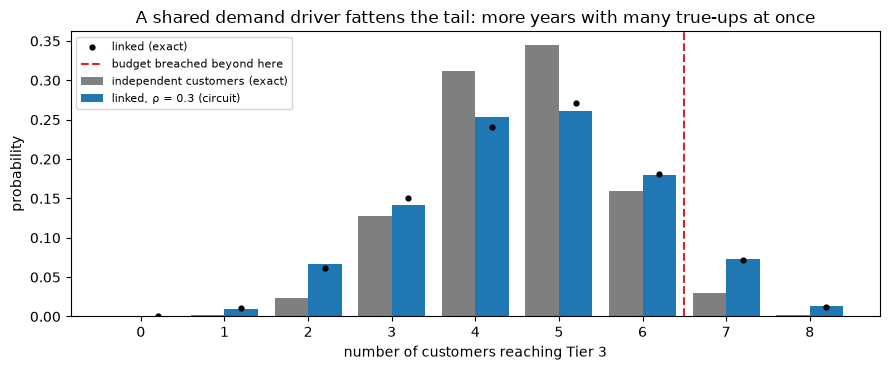


P(Tier 3 true-ups exceed £90,000) for this design
  exact (classical enumeration):          8.32%
  amplitude estimation (6,800 model runs): 8.43%   error 0.11%
  sampling with the same 6,800 runs:     8.62%   error 0.29%
  expected sampling error at 6,800 runs:  ±0.33%

Choosing the design: maximise the LTV score with P(breach) at most 5%
Tier 3 design       LTV score   true-up  P(breach) if  P(breach)  P(breach)  allowed
                                          independent      exact        QAE
 8,000 units @ 3%       65.8%    £6,000         0.00%      0.00%      0.00%      yes
 8,000 units @ 5%       72.8%   £14,000         3.10%      8.32%      8.32%       no
12,000 units @ 3%       30.6%    £9,000         0.00%      0.00%      0.00%      yes
12,000 units @ 5%       39.6%   £21,000         0.21%      1.06%      1.09%      yes

Best design: Tier 3 at 8,000 units, 3% (LTV score 65.8%, P(breach) 0.00%)
Treating customers as independent would choose Tier 3 at 8,000 units, 5%: its rea

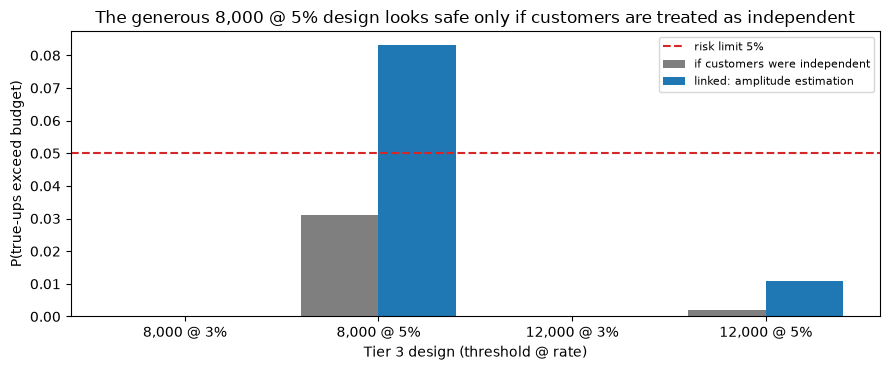

In [7]:
#A new quantum approach to constructing rebate programs
# Uses bernoulli_angle() from Part 4 and likelihood_estimate() / model_runs() from Part 6:
# run the Part 2, 4, 5 and 6 cells first.

from statistics import NormalDist

STD_NORMAL = NormalDist()


# --- 7.1 The rebate program and the design choices ------------------------------

PRICE = 50                    # £ per unit
T1, R1 = 2_000, 0.005         # Tier 1: fixed
T2, R2 = 5_000, 0.015         # Tier 2: fixed
DESIGNS = [(8_000, 0.03), (8_000, 0.05), (12_000, 0.03), (12_000, 0.05)]   # Tier 3 options (t3, r3)

BUDGET = 90_000               # £ available for Tier 3 true-ups this year
RISK_LIMIT = 0.05             # P(true-ups exceed the budget) must be at most 5%


def true_up(t3, r3):
    """Extra rebate triggered when a customer crosses Tier 3 (the cliff from Part 1.3)."""
    return (r3 - R2) * PRICE * t3


# --- 7.2 One qubit per customer ---------------------------------------------------

CUSTOMERS = [
    # name,  LTV group,  typical units, LTV weight, volume uplift per 1% of Tier 3 rate
    ("L1", "Low",  5_000, 1, 0.03),
    ("L2", "Low",  5_500, 1, 0.03),
    ("L3", "Low",  6_000, 1, 0.03),
    ("M1", "Mid",  7_000, 2, 0.05),
    ("M2", "Mid",  7_500, 2, 0.05),
    ("M3", "Mid",  8_000, 2, 0.05),
    ("H1", "High", 10_000, 4, 0.07),
    ("H2", "High", 11_000, 4, 0.07),
]
N_CUST = len(CUSTOMERS)
SPREAD = 0.35                 # volume standard deviation as a share of typical units
weights = np.array([c[3] for c in CUSTOMERS])


def reach_probs(t3, r3):
    """P(customer reaches Tier 3) for each customer, from their own volume curve."""
    return np.array([1 - NormalDist(mu * (1 + uplift * r3 * 100), SPREAD * mu).cdf(t3)
                     for _, _, mu, _, uplift in CUSTOMERS])


def ltv_score(t3, r3):
    """LTV-weighted expected share of customers reaching Tier 3 (the objective)."""
    p = reach_probs(t3, r3)
    return (weights * p).sum() / weights.sum()


# --- 7.3 Linking customers through a common demand driver Z ------------------------

RHO = 0.30                                    # share of volume surprise from the shared driver (illustrative)
Z_VALUES = np.array([-1.5, -0.5, 0.5, 1.5])   # weak to strong year for the shared driver
Z_PROBS = np.array([STD_NORMAL.pdf(z) for z in Z_VALUES])
Z_PROBS /= Z_PROBS.sum()


def conditional_probs(p, rho):
    """P(reach Tier 3 | Z = z) for each z and customer (Gaussian conditional independence)."""
    return np.array([[STD_NORMAL.cdf((STD_NORMAL.inv_cdf(pi) + np.sqrt(rho) * z) / np.sqrt(1 - rho))
                      for pi in np.clip(p, 1e-9, 1 - 1e-9)] for z in Z_VALUES])


def count_distribution(p, rho):
    """Exact classical check: distribution of how many customers reach Tier 3."""
    dist = np.zeros(N_CUST + 1)
    for z_prob, row in zip(Z_PROBS, conditional_probs(p, rho)):
        d = np.array([1.0])
        for pi in row:
            d = np.convolve(d, [1 - pi, pi])
        dist += z_prob * d
    return dist


def circuit_inputs(t3, r3, rho):
    """RY angles for the factor and customer qubits, and the largest affordable count."""
    factor = [bernoulli_angle(Z_PROBS[2] + Z_PROBS[3]),                 # high bit of z
              bernoulli_angle(Z_PROBS[1] / (Z_PROBS[0] + Z_PROBS[1])),  # low bit, if high bit = 0
              bernoulli_angle(Z_PROBS[3] / (Z_PROBS[2] + Z_PROBS[3]))]  # low bit, if high bit = 1
    customers = [bernoulli_angle(v) for row in conditional_probs(reach_probs(t3, r3), rho) for v in row]
    max_ok = int(BUDGET // true_up(t3, r3))                            # most Tier 3 customers affordable
    return factor, customers, max_ok


# --- 7.4 The circuit ------------------------------------------------------------------
# Qubits: 0-1 demand driver Z | 2-9 customers | 10-13 count | 14 objective

@cudaq.kernel
def load_model(q: cudaq.qview, factor_angles: list[float], cust_angles: list[float], max_ok: int):
    # 1. Demand driver Z: load P(z) into 2 qubits (q[1] = high bit, q[0] = low bit)
    ry(factor_angles[0], q[1])
    x(q[1])
    ry.ctrl(factor_angles[1], q[1], q[0])
    x(q[1])
    ry.ctrl(factor_angles[2], q[1], q[0])
    # 2. One Bernoulli qubit per customer, rotated by P(reach Tier 3 | z)
    for zv in range(4):
        if zv & 1 == 0:
            x(q[0])
        if zv & 2 == 0:
            x(q[1])
        for i in range(8):
            ry.ctrl(cust_angles[zv * 8 + i], q[0], q[1], q[2 + i])
        if zv & 1 == 0:
            x(q[0])
        if zv & 2 == 0:
            x(q[1])
    # 3. Count register: add 1 for every customer who reaches Tier 3
    for i in range(8):
        x.ctrl(q[2 + i], q[10], q[11], q[12], q[13])
        x.ctrl(q[2 + i], q[10], q[11], q[12])
        x.ctrl(q[2 + i], q[10], q[11])
        x.ctrl(q[2 + i], q[10])
    # 4. Objective qubit: 1 if the count is more than the budget can pay for
    for v in range(max_ok + 1, 9):
        for b in range(4):
            if (v >> b) & 1 == 0:
                x(q[10 + b])
        x.ctrl(q[10], q[11], q[12], q[13], q[14])
        for b in range(4):
            if (v >> b) & 1 == 0:
                x(q[10 + b])


@cudaq.kernel
def unload_model(q: cudaq.qview, factor_angles: list[float], cust_angles: list[float], max_ok: int):
    # The same gates as load_model, in reverse order with negated angles (A†)
    for j in range(8 - max_ok):
        v = 8 - j
        for b in range(4):
            if (v >> b) & 1 == 0:
                x(q[10 + b])
        x.ctrl(q[10], q[11], q[12], q[13], q[14])
        for b in range(4):
            if (v >> b) & 1 == 0:
                x(q[10 + b])
    for j in range(8):
        i = 7 - j
        x.ctrl(q[2 + i], q[10])
        x.ctrl(q[2 + i], q[10], q[11])
        x.ctrl(q[2 + i], q[10], q[11], q[12])
        x.ctrl(q[2 + i], q[10], q[11], q[12], q[13])
    for j in range(4):
        zv = 3 - j
        if zv & 1 == 0:
            x(q[0])
        if zv & 2 == 0:
            x(q[1])
        for jj in range(8):
            i = 7 - jj
            ry.ctrl(-cust_angles[zv * 8 + i], q[0], q[1], q[2 + i])
        if zv & 1 == 0:
            x(q[0])
        if zv & 2 == 0:
            x(q[1])
    ry.ctrl(-factor_angles[2], q[1], q[0])
    x(q[1])
    ry.ctrl(-factor_angles[1], q[1], q[0])
    x(q[1])
    ry(-factor_angles[0], q[1])


@cudaq.kernel
def rebate_risk(factor_angles: list[float], cust_angles: list[float], max_ok: int, k: int):
    q = cudaq.qvector(15)
    load_model(q, factor_angles, cust_angles, max_ok)                 # A
    for step in range(k):                                             # Grover operator Q, k times
        z(q[14])                                                      #   mark: budget breached
        unload_model(q, factor_angles, cust_angles, max_ok)           #   undo A
        x(q)
        z.ctrl(q.front(14), q[14])                                    #   reflect about |0...0>
        x(q)
        load_model(q, factor_angles, cust_angles, max_ok)             #   redo A


def breach_hits(inputs, k, shots):
    counts = cudaq.sample(rebate_risk, *inputs, k, shots_count=shots)
    return sum(c for bits, c in counts.items() if bits[14] == "1")


def count_from_bits(bits):
    return sum(int(bits[10 + b]) << b for b in range(4))


# --- The model, checked customer by customer and as a portfolio ---------------------

t3, r3 = 8_000, 0.05
p = reach_probs(t3, r3)
inputs = circuit_inputs(t3, r3, RHO)
SAMPLES = 4_000
counts = cudaq.sample(rebate_risk, *inputs, 0, shots_count=SAMPLES)

print(f"Design: Tier 3 at {t3:,} units, {r3:.0%}.  True-up per customer: £{true_up(t3, r3):,.0f}")
print(f"Budget £{BUDGET:,} pays for at most {inputs[2]} customers reaching Tier 3\n")
print(f"{'Customer':<9}{'LTV':<6}{'P(reach Tier 3)':>16}{'measured':>10}")
for i, (name, group, *_rest) in enumerate(CUSTOMERS):
    measured = sum(c for bits, c in counts.items() if bits[2 + i] == "1") / SAMPLES
    print(f"{name:<9}{group:<6}{p[i]:>16.1%}{measured:>10.1%}")

dist_corr = count_distribution(p, RHO)
dist_indep = count_distribution(p, 1e-9)
circuit_counts = np.zeros(N_CUST + 1)
for bits, c in counts.items():
    circuit_counts[count_from_bits(bits)] += c / SAMPLES

fig, ax = plt.subplots(figsize=(9, 3.8))
n_reach = np.arange(N_CUST + 1)
ax.bar(n_reach - 0.2, dist_indep, width=0.4, color="tab:grey", label="independent customers (exact)")
ax.bar(n_reach + 0.2, circuit_counts, width=0.4, color="tab:blue", label=f"linked, ρ = {RHO} (circuit)")
ax.scatter(n_reach + 0.2, dist_corr, color="black", s=12, zorder=3, label="linked (exact)")
ax.axvline(inputs[2] + 0.5, color="tab:red", linestyle="--", label="budget breached beyond here")
ax.set_xticks(n_reach)
ax.set_xlabel("number of customers reaching Tier 3")
ax.set_ylabel("probability")
ax.set_title("A shared demand driver fattens the tail: more years with many true-ups at once")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


# --- 7.5 Estimating P(budget breached) with amplitude estimation --------------------

SCHEDULE = [0, 1, 2, 4, 8, 16]
SHOTS_PER_K = 100

exact = dist_corr[inputs[2] + 1:].sum()
hits = [breach_hits(inputs, k, SHOTS_PER_K) for k in SCHEDULE]
qae_estimate = likelihood_estimate(hits, SHOTS_PER_K, SCHEDULE)[0]
runs = model_runs(SCHEDULE, SHOTS_PER_K)
mc_estimate = breach_hits(inputs, 0, runs) / runs

print(f"\nP(Tier 3 true-ups exceed £{BUDGET:,}) for this design")
print(f"  exact (classical enumeration):          {exact:.2%}")
print(f"  amplitude estimation ({runs:,} model runs): {qae_estimate:.2%}   error {abs(qae_estimate - exact):.2%}")
print(f"  sampling with the same {runs:,} runs:     {mc_estimate:.2%}   error {abs(mc_estimate - exact):.2%}")
print(f"  expected sampling error at {runs:,} runs:  ±{np.sqrt(exact * (1 - exact) / runs):.2%}")


# --- 7.6 Choosing the design ---------------------------------------------------------

print(f"\nChoosing the design: maximise the LTV score with P(breach) at most {RISK_LIMIT:.0%}")
print(f"{'Tier 3 design':<19}{'LTV score':>10}{'true-up':>10}{'P(breach) if':>14}{'P(breach)':>11}"
      f"{'P(breach)':>11}{'allowed':>9}")
print(f"{'':<19}{'':>10}{'':>10}{'independent':>14}{'exact':>11}{'QAE':>11}")

rows = []
for t3, r3 in DESIGNS:
    p = reach_probs(t3, r3)
    inputs = circuit_inputs(t3, r3, RHO)
    indep = count_distribution(p, 1e-9)[inputs[2] + 1:].sum()
    exact = count_distribution(p, RHO)[inputs[2] + 1:].sum()
    hits = [breach_hits(inputs, k, SHOTS_PER_K) for k in SCHEDULE]
    qae = likelihood_estimate(hits, SHOTS_PER_K, SCHEDULE)[0]
    allowed = qae <= RISK_LIMIT
    rows.append((t3, r3, ltv_score(t3, r3), indep, exact, qae, allowed))
    print(f"{t3:>6,} units @ {r3:.0%}  {ltv_score(t3, r3):>10.1%}{f'£{true_up(t3, r3):,.0f}':>10}"
          f"{indep:>14.2%}{exact:>11.2%}{qae:>11.2%}{'yes' if allowed else 'no':>9}")

best = max((r for r in rows if r[6]), key=lambda r: r[2])
naive = max((r for r in rows if r[3] <= RISK_LIMIT), key=lambda r: r[2])
print(f"\nBest design: Tier 3 at {best[0]:,} units, {best[1]:.0%} "
      f"(LTV score {best[2]:.1%}, P(breach) {best[5]:.2%})")
print(f"Treating customers as independent would choose Tier 3 at {naive[0]:,} units, {naive[1]:.0%}: "
      f"its real P(breach) is {naive[4]:.1%}, over the {RISK_LIMIT:.0%} limit.")

fig, ax = plt.subplots(figsize=(9, 3.8))
labels = [f"{t3:,} @ {r3:.0%}" for t3, r3, *_ in rows]
positions = np.arange(len(rows))
ax.bar(positions - 0.2, [r[3] for r in rows], width=0.4, color="tab:grey", label="if customers were independent")
ax.bar(positions + 0.2, [r[5] for r in rows], width=0.4, color="tab:blue", label="linked: amplitude estimation")
ax.axhline(RISK_LIMIT, color="tab:red", linestyle="--", label=f"risk limit {RISK_LIMIT:.0%}")
ax.set_xticks(positions, labels)
ax.set_xlabel("Tier 3 design (threshold @ rate)")
ax.set_ylabel("P(true-ups exceed budget)")
ax.set_title("The generous 8,000 @ 5% design looks safe only if customers are treated as independent")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
